# Filtrado inverso para identificar la frecuencia de puentes con teléfonos en vehículos

**Referencia:** Shirzad-Ghaleroudkhani, N. y Gül, M. (2020). *Inverse Filtering for Frequency Identification of Bridges Using Smartphones in Passing Vehicles: Fundamental Developments and Laboratory Verifications*. Sensors, 20(4), 1190. https://doi.org/10.3390/s20041190

**PDF:** [2020-shirzad-ghaleroudkhani-inverse-filtering-bridge-frequency.pdf](2020-shirzad-ghaleroudkhani-inverse-filtering-bridge-frequency.pdf)

**El artículo en una frase:** el mismo teléfono, en el mismo auto, registra la vibración **fuera** del puente y **sobre** el puente; el espectro de fuera del puente se invierte para construir un filtro que borra las frecuencias propias del auto y del teléfono, y al aplicarlo al espectro de sobre el puente queda resaltada la **frecuencia fundamental del puente**.

> **Sobre los ejemplos de código.** El artículo es experimental (un auto robot sobre un puente de laboratorio) y sus datos no son públicos. Los ejemplos reproducen el ensayo con una **simulación propia simplificada**; varios parámetros que el artículo no reporta se suponen y se indican como tales. Sus números no son los del artículo. Los valores **reportados por el artículo** se indican siempre de forma explícita; los que se leen de sus gráficas son aproximados.

<a id="indice"></a>
## Índice

- [Glosario](#glosario)
1. [Problema](#problema)
2. [Propósito](#proposito)
3. [Conceptos clave](#conceptos)
    - 3.1 [Interacción vehículo–puente (VBI)](#c-vbi)
    - 3.2 [ADFT: espectro promediado por ventanas](#c-adft)
    - 3.3 [Filtro inverso](#c-inv)
    - 3.4 [Prominencia de un pico](#c-prom)
4. [Metodología](#metodologia)
    - 4.1 [Interacción vehículo–puente](#m-vbi)
    - 4.2 [Del tiempo a la frecuencia: DFT y ADFT](#m-adft)
    - 4.3 [Diseño y aplicación del filtro inverso](#m-inv)
    - 4.4 [Puntuación de picos](#m-score)
5. [Procedimiento](#procedimiento)
    - 5.1 [Puente de laboratorio](#p-puente)
    - 5.2 [Auto robot](#p-auto)
    - 5.3 [Instrumentos: sensor y teléfono](#p-instr)
    - 5.4 [Simulación de los ensayos](#p-sim)
    - 5.5 [Procesamiento de las señales](#p-proc)
6. [Resultados](#resultados)
    - 6.1 [Espectros fuera del puente y forma del filtro](#r-off)
    - 6.2 [Verificación del filtro con datos nuevos fuera del puente](#r-verif)
    - 6.3 [Aplicación del filtro sobre el puente](#r-on)
    - 6.4 [Puntuación de picos](#r-score)
    - 6.5 [Sensibilidad a los supuestos del método](#r-sens)
7. [Conclusiones y limitaciones](#conclusiones)

<a id="glosario"></a>
## Glosario

Términos y siglas que aparecen en este notebook, agrupados por tema. Los marcados con → tienen una ficha completa en [Conceptos clave](#conceptos).

**Monitoreo de puentes**

- **SHM** (*Structural Health Monitoring*, monitoreo de la salud estructural): seguimiento del estado de una estructura con mediciones, para detectar daño a tiempo.
- **Monitoreo indirecto o *drive-by*:** medir la vibración del puente con sensores en un vehículo que lo cruza, en lugar de sensores fijos en el puente (ver la [ficha del notebook de Zeng et al., 2025](../2025-zeng-mishm-multibridge-drive-by-shm/2025-zeng-mishm-multibridge-drive-by-shm.ipynb#c-driveby)).
- ***Crowdsourcing*** (o *crowdsensing*): recolectar datos con los dispositivos de mucha gente, p. ej. los teléfonos de los pasajeros.
- **Ciudad inteligente** (*smart city*): ciudad que usa sensores, cómputo y comunicaciones para gestionar mejor su infraestructura.
- **Fuera del puente / sobre el puente** (*off-bridge / on-bridge*): señal registrada mientras el vehículo circula por el suelo / por el puente.

**Dinámica estructural**

- **Frecuencia natural** ($f_n$, en Hz): frecuencia a la que una estructura vibra libremente en su modo $n$. La **frecuencia fundamental** es la más baja ($f_1$).
- **Modo de vibración:** forma característica en que vibra la estructura a cada frecuencia natural.
- **Viga simplemente apoyada:** viga con un apoyo **articulado** (*pin*: impide desplazarse pero deja girar) y uno **de rodillo** (*roller*: además deja desplazarse en horizontal).
- **Rigidez a flexión** ($EI$): módulo de elasticidad por momento de inercia de la sección; resistencia de la viga a flexionarse.
- **Amortiguamiento** ($\zeta$): disipación de energía que hace que la vibración libre decaiga; se expresa como fracción del amortiguamiento crítico.
- **Vibración libre:** vibración después de una perturbación inicial, sin fuerzas externas. El **ensayo de vibración libre** del artículo desplaza el centro del puente y lo suelta.
- **Resonancia:** gran amplificación de la respuesta cuando la excitación tiene una frecuencia cercana a una frecuencia natural.
- **VBI** (*Vehicle–Bridge Interaction*) → [3.1](#c-vbi): acoplamiento dinámico entre vehículo y puente.
- **Sistema masa–resorte:** modelo simple de vehículo: una masa sobre un resorte.
- **Suspensión; masa suspendida y no suspendida:** la suspensión son los resortes entre ruedas y carrocería. La masa suspendida está sobre los resortes (aquí la placa superior con el teléfono); la no suspendida está bajo ellos (placa inferior, motores y ruedas).
- **Relación de masas:** masa del vehículo dividida por la masa del puente.
- **Rugosidad:** pequeñas irregularidades de la superficie por la que ruedan las ruedas; excitan al vehículo.
- **Armónicos:** frecuencias múltiplos enteros de una frecuencia fundamental ($2f$, $3f$, …). El motor y las ruedas generan armónicos proporcionales a la velocidad.

**Procesamiento de señales**

- **Frecuencia de muestreo** ($f_s$): muestras por segundo. La **frecuencia de Nyquist** ($f_s/2$) es la máxima frecuencia que se puede representar.
- ***Jitter***: irregularidad del intervalo entre muestras; típico de los teléfonos, que no muestrean a intervalos exactamente fijos.
- **Remuestreo por interpolación:** calcular la señal en instantes regulares a partir de muestras irregulares.
- **DFT / FFT:** transformada discreta de Fourier y su algoritmo rápido; descomponen una señal en senos y cosenos de distintas frecuencias.
- **Espectro de amplitud:** amplitud de cada frecuencia en la señal (aquí en m/s²).
- **Resolución en frecuencia:** separación mínima entre dos frecuencias que se pueden distinguir; es aproximadamente $1/T$, donde $T$ es la duración del tramo analizado.
- **Ventana; ventana de Hamming:** función que multiplica un tramo de señal para que empiece y termine suavemente. Reduce la **fuga espectral** (*leakage*): energía de un pico que se "derrama" a frecuencias vecinas.
- **Solapamiento** (*overlap*): fracción de muestras que comparten dos ventanas consecutivas.
- **Relleno con ceros** (*zero padding*): agregar ceros al final de un tramo antes de la DFT. Da puntos de frecuencia más juntos (interpola el espectro), pero **no** mejora la resolución real.
- **ADFT** (*Averaged DFT*) → [3.2](#c-adft): promedio de los espectros de varias ventanas; también llamado método de Welch.
- **Filtro; función de transferencia:** un filtro modifica cada frecuencia de una señal; la función de transferencia dice por cuánto multiplica cada una.
- **Filtro inverso** → [3.3](#c-inv): filtro cuya forma es el inverso de un espectro conocido; deshace su efecto. También se le llama **deconvolución** o **blanqueo espectral**.
- **Ruido blanco:** señal aleatoria con la misma amplitud media en todas las frecuencias (espectro plano).
- **Pico; prominencia** → [3.4](#c-prom): máximo local del espectro; cuánto sobresale respecto de su entorno.
- **Puntuación de picos:** calificación de 0 a 100 que el artículo da a cada pico según su amplitud y su prominencia.
- **Histograma:** gráfico de barras que agrupa valores en intervalos (aquí, intervalos de frecuencia).

**Instrumentos**

- **Acelerómetro:** sensor que mide aceleración. El **G-Link-200** es un acelerómetro inalámbrico comercial (LORD MicroStrain) que se usa como referencia.
- **Giroscopio y magnetómetro:** sensores del teléfono que miden giro y campo magnético; la aplicación de los autores los usa para obtener la aceleración **vertical global** aunque el teléfono esté inclinado.
- **MATLAB:** programa de cálculo que usan los autores para analizar los picos.

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle, Polygon, Circle
from IPython.display import display, Markdown
from scipy.signal import find_peaks, peak_prominences

SEED = 42
rng = np.random.default_rng(SEED)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})


# Display a table with its caption above it
def show_table(df, number, caption, precision=2, hide_index=False):
    display(Markdown(f"**Tabla {number}.** {caption}"))
    styled = df.style.format(precision=precision)
    display(styled.hide(axis="index") if hide_index else styled)


# Display a figure with its caption below it
def show_figure(fig, number, caption):
    display(fig)
    plt.close(fig)
    display(Markdown(f"**Figura {number}.** {caption}"))

<a id="problema"></a>
## 1. Problema

- **Puentes envejecidos.** Según el *Canadian Infrastructure Report Card* (2016), cerca del 26 % de los puentes de Canadá está en estado "regular", "malo" o "muy malo" y necesita monitoreo.
- **Los sensores fijos no escalan.** Instrumentar cada puente es caro y lento; no se puede hacer en todos los puentes de una ciudad.
- **El monitoreo indirecto es una alternativa.** Un vehículo que cruza el puente vibra junto con él, así que su aceleración contiene información del puente (Yang et al., 2004). Con los teléfonos de los pasajeros, los datos podrían venir de miles de cruces (*crowdsourcing*).
- **El obstáculo.** La vibración del vehículo está dominada por **sus propias características** (suspensión, masa, velocidad, motor), no por el puente. La frecuencia del puente queda escondida entre los picos del vehículo.
- **Vacío que ataca el artículo.** Filtrar esos picos es difícil porque **cada señal viene de un teléfono distinto en un vehículo distinto**: un filtro general no sirve. Hace falta un filtro **propio de cada vehículo y de cada teléfono**, que se pueda construir sin conocer sus propiedades.

<a id="proposito"></a>
## 2. Propósito

**Objetivo:** proponer un método de **filtrado inverso** que use la vibración del vehículo **fuera del puente** para eliminar las frecuencias propias del vehículo y del teléfono de la vibración registrada **sobre el puente**, e identificar así la **frecuencia fundamental del puente**.

**Aportes:**

1. Según los autores, es el primer método de filtrado inverso para identificar indirectamente la frecuencia de un puente.
2. El filtro se diseña **para cada dispositivo en cada vehículo** con sus propios datos, así que no hace falta conocer las propiedades del vehículo ni del teléfono.
3. Verificación en laboratorio con un auto robot sobre un puente de acero, en **9 combinaciones** de velocidad y rigidez de suspensión, comparando un **teléfono** con un **acelerómetro de referencia**.

**Pregunta central:** ¿si se divide el espectro de sobre el puente por el de fuera del puente, la frecuencia fundamental del puente pasa a ser el pico dominante, sea cual sea la velocidad, la suspensión y el dispositivo?

<a id="conceptos"></a>
## 3. Conceptos clave

El artículo se apoya en cuatro ideas. Aquí se explica qué es cada una, para qué sirve, por qué se eligió y cuándo conviene o no usarla. Cómo las aplica el artículo (fórmulas y código) está en la [Metodología](#metodologia).

<a id="c-vbi"></a>
### 3.1 Interacción vehículo–puente (VBI)

**Qué es.** VBI son las siglas de *Vehicle–Bridge Interaction*. Cuando un vehículo cruza un puente, el peso del vehículo hace vibrar al puente y la vibración del puente mueve las ruedas del vehículo: las dos vibraciones quedan **acopladas**. Yang, Lin y Yau (2004) mostraron con un modelo de viga y una masa–resorte móvil que la respuesta del vehículo contiene la frecuencia del puente; es la base del **monitoreo indirecto**.

**Para qué sirve.** Para extraer propiedades del puente (frecuencias, formas modales, daño) a partir de la vibración de un vehículo que lo cruza, sin sensores en el puente.

**Por qué se usó en este artículo.** Es el principio físico que justifica todo el método: si la vibración del vehículo sobre el puente contiene la del puente, y la del vehículo fuera del puente no, la diferencia entre ambas es el puente.

**Cuándo conviene.**

- Muchos puentes que monitorear con poco presupuesto.
- Cuando interesa una medida global (frecuencia fundamental) más que una local.
- Cuando el vehículo cruza a velocidad baja y constante: la señal es más larga y más limpia.

**Cuándo no conviene.**

- Cuando la frecuencia del vehículo está muy cerca de la del puente: sus picos se mezclan.
- Con mucha rugosidad o a alta velocidad: la vibración del vehículo tapa la del puente.
- Cuando se necesitan medidas precisas o continuas en el tiempo: los sensores fijos son más exactos.

**Alternativas.** Sensores fijos en el puente (monitoreo directo); vehículos instrumentados dedicados; respuesta en el punto de contacto rueda–puente, que elimina la frecuencia del vehículo (Yang et al., 2018); métodos estadísticos sobre muchos cruces (MFCC con [Zeng et al., 2025](../2025-zeng-mishm-multibridge-drive-by-shm/2025-zeng-mishm-multibridge-drive-by-shm.ipynb#c-driveby)).

<a id="c-adft"></a>
### 3.2 ADFT: espectro promediado por ventanas

**Qué es.** ADFT es el nombre que usa el artículo para la *Averaged Discrete Fourier Transform*: la señal se corta en tramos (**ventanas**) que se solapan, a cada tramo se le aplica una ventana suave (Hamming) y una DFT, y se **promedian** las amplitudes de todos los espectros. En la literatura se conoce como **método de Welch** (Welch, 1967), que normalmente promedia potencias en lugar de amplitudes.

**Para qué sirve.** Para estimar un espectro **suave y estable**. El espectro de un solo tramo (o de toda la señal) fluctúa mucho por el ruido; al promediar $M$ espectros, esa fluctuación baja aproximadamente como $1/\sqrt{M}$.

**Por qué se usó en este artículo.** El filtro se construye **dividiendo por el espectro**: si el espectro fluctúa, el filtro también, y amplifica valles aleatorios. Además, al promediar, un evento aislado (un golpe en una ventana) pesa poco en el espectro final.

**Cuándo conviene.**

- Señales estacionarias (sus propiedades no cambian en el tiempo) y suficientemente largas para varias ventanas.
- Cuando importa más la forma general del espectro que la resolución fina.

**Cuándo no conviene.**

- Señales muy cortas: con ventanas de 3 s y señales de 4–8 s solo hay unas pocas ventanas para promediar.
- Cuando se necesita resolución fina: ventanas más cortas dan una resolución peor, $\Delta f \approx 1/T_w$.
- Señales no estacionarias, como la de un vehículo que cruza un puente: la frecuencia acoplada cambia con la posición del vehículo.

**Alternativas.** Periodograma suavizado; método multitaper; espectros paramétricos (modelos autorregresivos); transformadas tiempo–frecuencia (espectrograma, wavelets) para señales no estacionarias.

<a id="c-inv"></a>
### 3.3 Filtro inverso

**Qué es.** Un filtro cuya función de transferencia es el **inverso de un espectro conocido**: multiplica cada frecuencia por $1/X(f)$. Deshace el efecto de un sistema conocido; en procesamiento de señales se llama **deconvolución**, y cuando el resultado queda con espectro plano, **blanqueo espectral**. Sus primeros usos fueron en el análisis de la voz (Markel, 1972: separar la fuente de la voz del filtro del tracto vocal) y luego en imágenes médicas y geofísica.

**Para qué sirve.** Para quitar de una señal la contribución de algo que se conoce (aquí, el vehículo y el teléfono) y dejar a la vista lo que es **nuevo** (el puente). Equivale a calcular el **cociente** entre dos espectros: lo que está en ambos se cancela y lo que solo está en uno sobresale.

**Por qué se usó en este artículo.** Cada vehículo y cada teléfono tienen un espectro propio, así que no sirve un filtro general. La señal de fuera del puente es una **referencia gratuita**: la registra el mismo teléfono, en el mismo vehículo, poco antes de cruzar. Con ella se construye un filtro a medida sin conocer las propiedades del vehículo.

**Cuándo conviene.**

- La contribución que se quiere quitar es igual en la referencia y en la medición: misma velocidad, misma superficie, misma posición del teléfono.
- Lo que se busca (la frecuencia del puente) **no coincide** con un pico grande de la referencia.

**Cuándo no conviene.**

- Si las condiciones cambian entre la referencia y la medición: los picos ya no se cancelan y aparecen picos falsos.
- Si la frecuencia buscada está sobre un pico del vehículo: el filtro la atenúa en lugar de resaltarla.
- Si la referencia tiene valores casi nulos en alguna frecuencia: al dividir se amplifica el ruido. Se suele **regularizar**, p. ej. con el filtro de Wiener $X^*/(|X|^2 + \varepsilon)$, donde $X^*$ es el conjugado de $X$ y $\varepsilon$ una constante pequeña.

**Alternativas.** Deconvolución regularizada (Wiener); restar espectros en escala logarítmica (la idea detrás de los MFCC y el *cepstrum*, ver [Zeng et al., 2025](../2025-zeng-mishm-multibridge-drive-by-shm/2025-zeng-mishm-multibridge-drive-by-shm.ipynb#c-mfcc)); cocientes entre los dos ejes del vehículo; filtros adaptativos; respuesta en el punto de contacto.

<a id="c-prom"></a>
### 3.4 Prominencia de un pico

**Qué es.** Una medida de cuánto **sobresale** un pico respecto de su entorno. Se toma de la topografía (la prominencia de una montaña): desde el pico se avanza hacia cada lado hasta encontrar un pico más alto (o el borde); en cada lado se anota el punto más bajo recorrido. La prominencia es la altura del pico sobre **el más alto** de esos dos puntos bajos. Está implementada en MATLAB (`findpeaks`) y en SciPy (`peak_prominences`).

**Para qué sirve.** Para ordenar picos de forma automática. Un pico bajo pero aislado puede ser más prominente que uno alto que está en medio de otros picos altos.

**Por qué se usó en este artículo.** Para medir de forma objetiva si el filtro hace que la frecuencia del puente destaque: los autores califican cada pico con su amplitud **y** su prominencia.

**Cuándo conviene.** Elegir picos dominantes en espectros con ruido; comparar espectros de forma automática.

**Cuándo no conviene.** Picos superpuestos (la prominencia de uno depende del otro); espectros muy ruidosos con muchos picos pequeños; resultados que dependen del rango de frecuencias elegido, porque los bordes cambian la prominencia.

**Alternativas.** Umbral de amplitud; relación pico–ruido; ancho del pico; identificación modal (que da frecuencias y amortiguamientos con incertidumbre).

<a id="metodologia"></a>
## 4. Metodología

El método tiene tres pasos (Sección 2 del artículo): pasar las aceleraciones al dominio de la frecuencia con la ADFT, diseñar el filtro inverso con la señal de fuera del puente y aplicarlo al espectro de sobre el puente. Para medir el resultado, los autores califican los picos del espectro filtrado (Sección 4.3). Las fichas de cada concepto están en [Conceptos clave](#conceptos); aquí se siguen las ecuaciones.

<a id="m-vbi"></a>
### 4.1 Interacción vehículo–puente

Qué es la VBI está en la [ficha 3.1](#c-vbi). El artículo parte del modelo de Yang y Yau: una viga (el puente) y una masa–resorte que la recorre a velocidad $v$ (el vehículo). Escrito con la notación habitual (Ec. 1 del artículo):

$$\begin{cases} \bar{m}\,\ddot{u}_b(x,t) + EI\,\dfrac{\partial^4 u_b(x,t)}{\partial x^4} = p(x,t) \\[2ex] m_v\,\ddot{u}_v(t) + k_v\left[u_v(t) - u_b(vt,\,t)\right] = 0 \end{cases} \tag{1}$$

donde:

- $u_b(x,t)$: desplazamiento vertical del puente en la posición $x$ y el instante $t$; $\bar{m}$: masa del puente por unidad de longitud; $E$ e $I$: módulo de elasticidad y momento de inercia de la sección.
- $p(x,t)$: fuerza de contacto que el vehículo aplica en el punto donde está ($x = vt$).
- $u_v(t)$: desplazamiento vertical del vehículo; $m_v$ y $k_v$: su masa y la rigidez de su suspensión.
- Los puntos indican derivadas en el tiempo; la derivada cuarta es en el espacio.

**Por qué importa.** La segunda ecuación muestra que el vehículo se mueve empujado por $u_b(vt,t)$, el desplazamiento del puente bajo la rueda. Por eso su aceleración contiene la frecuencia del puente, **además** de la suya propia. Fuera del puente, $u_b = 0$ y solo queda el vehículo. Esa diferencia es la que aprovecha el filtro.

La Figura 1 muestra el esquema de las dos situaciones del ensayo.

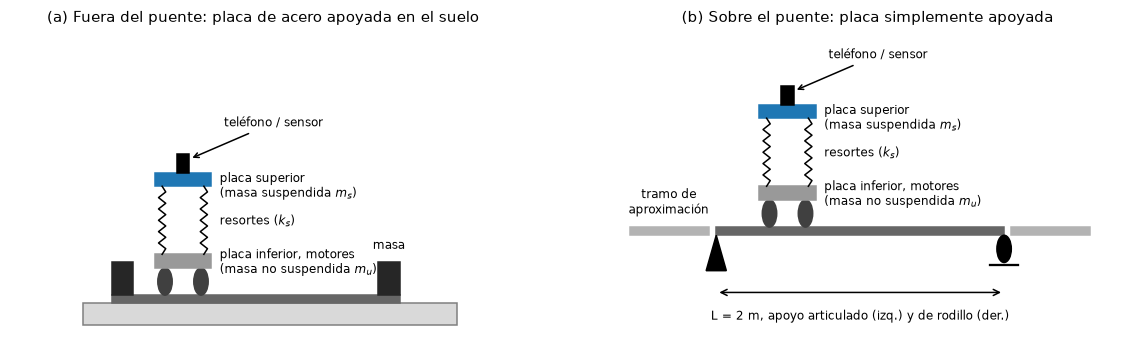

**Figura 1.** Esquema del ensayo (propio, basado en las Figs. 6, 8 y 11 del artículo). El mismo auto y el mismo teléfono recorren una placa sobre el suelo (a) y el puente (b). Dimensiones verticales exageradas.

In [2]:
def draw_spring(ax, x, y0, y1, n=6, w=0.025, **kw):
    # Zig-zag spring between heights y0 and y1 at abscissa x
    ys = np.linspace(y0, y1, 2 * n + 1)
    xs = x + np.r_[0, np.tile([w, -w], n - 1), w, 0][:ys.size]
    ax.plot(xs, ys, **kw)


def draw_car(ax, x0, y0, color="tab:blue"):
    # Two-axle car: wheels, bottom plate (unsprung), springs and top plate (sprung) with phone
    for xw in (x0 + 0.07, x0 + 0.32):
        ax.add_patch(Circle((xw, y0 + 0.05), 0.05, color="0.25"))
    ax.add_patch(Rectangle((x0, y0 + 0.10), 0.39, 0.05, color="0.6"))
    for xs in (x0 + 0.05, x0 + 0.34):
        draw_spring(ax, xs, y0 + 0.15, y0 + 0.40, color="k", lw=1)
    ax.add_patch(Rectangle((x0, y0 + 0.40), 0.39, 0.05, color=color))
    ax.add_patch(Rectangle((x0 + 0.15, y0 + 0.45), 0.09, 0.07, color="k"))
    ax.annotate("teléfono / sensor", (x0 + 0.24, y0 + 0.50), (x0 + 0.48, y0 + 0.62),
                arrowprops=dict(arrowstyle="->"), fontsize=8)
    ax.text(x0 + 0.45, y0 + 0.40, "placa superior\n(masa suspendida $m_s$)", fontsize=8, va="center")
    ax.text(x0 + 0.45, y0 + 0.27, "resortes ($k_s$)", fontsize=8, va="center")
    ax.text(x0 + 0.45, y0 + 0.12, "placa inferior, motores\n(masa no suspendida $m_u$)", fontsize=8, va="center")


fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
# (a) off-bridge: plate on the ground restrained by end masses
ax = axes[0]
ax.add_patch(Rectangle((-0.2, -0.08), 2.6, 0.08, color="0.85", hatch="///", ec="0.5"))
ax.add_patch(Rectangle((0, 0), 2.0, 0.03, color="0.4"))
for xm in (0.0, 1.85):
    ax.add_patch(Rectangle((xm, 0.03), 0.15, 0.12, color="0.15"))
ax.text(1.925, 0.2, "masa", ha="center", fontsize=8)
draw_car(ax, 0.3, 0.03)
ax.set_title("(a) Fuera del puente: placa de acero apoyada en el suelo", fontsize=10)
# (b) on-bridge: simply supported plate with approach and end spans
ax = axes[1]
yb = 0.25
ax.add_patch(Rectangle((0, yb), 2.0, 0.03, color="0.4"))
ax.add_patch(Rectangle((-0.6, yb), 0.55, 0.03, color="0.7"))
ax.add_patch(Rectangle((2.05, yb), 0.55, 0.03, color="0.7"))
ax.add_patch(Polygon([[0, yb], [-0.07, yb - 0.13], [0.07, yb - 0.13]], color="k"))
ax.add_patch(Circle((2.0, yb - 0.05), 0.05, color="k"))
ax.plot([1.9, 2.1], [yb - 0.11, yb - 0.11], "k")
draw_car(ax, 0.3, yb + 0.03)
ax.annotate("", (0, 0.04), (2.0, 0.04), arrowprops=dict(arrowstyle="<->"))
ax.text(1.0, -0.06, "L = 2 m, apoyo articulado (izq.) y de rodillo (der.)", ha="center", fontsize=8)
ax.text(-0.33, yb + 0.08, "tramo de\naproximación", ha="center", fontsize=8)
ax.set_title("(b) Sobre el puente: placa simplemente apoyada", fontsize=10)
for ax in axes:
    ax.set_xlim(-0.7, 2.8)
    ax.set_ylim(-0.12, 1.0)
    ax.axis("off")
show_figure(fig, 1, "Esquema del ensayo (propio, basado en las Figs. 6, 8 y 11 del artículo). El mismo auto y el mismo "
                    "teléfono recorren una placa sobre el suelo (a) y el puente (b). Dimensiones verticales exageradas.")

<a id="m-adft"></a>
### 4.2 Del tiempo a la frecuencia: DFT y ADFT

Qué es la ADFT y por qué se eligió está en la [ficha 3.2](#c-adft).

**Paso 1. DFT.** La aceleración $a[n]$, con $N$ muestras, se descompone en frecuencias (Ecs. 2 y 3 del artículo):

$$X[k] = \sum_{n=0}^{N-1} a[n]\, e^{-j\frac{2\pi}{N}kn} \tag{2}$$

$$f_k = \frac{k}{N}\, f_s, \qquad 0 \le k \le N-1 \tag{3}$$

donde $X[k]$ es un número complejo (amplitud y fase) asociado a la frecuencia $f_k$, $f_s$ es la frecuencia de muestreo y $j$ la unidad imaginaria. La DFT de la señal completa da un espectro muy irregular (Fig. 1 del artículo), poco útil para dividir por él.

**Paso 2. Ventanas.** La señal se corta en tramos de $N_w$ muestras y cada tramo se multiplica por una ventana de Hamming (Ec. 4 del artículo, escrita centrada en cero):

$$w[n] = 0.54 + 0.46\cos\!\left(\frac{2\pi n}{N_w - 1}\right), \qquad |n| \le \frac{N_w - 1}{2} \tag{4}$$

La ventana vale 1 en el centro y 0.08 en los extremos: así el tramo empieza y termina suavemente y se reduce la fuga espectral.

**Paso 3. Promedio.** Las ventanas avanzan $H = (1-p)\,N_w$ muestras cada vez, con solapamiento $p$. El espectro promediado es:

$$\bar{X}[k] = \frac{1}{M} \sum_{m=1}^{M} \left|\, \sum_{n=0}^{N_w-1} w[n]\; a\big[n + (m-1)H\big]\; e^{-j\frac{2\pi}{N_{\text{fft}}}kn} \right| \tag{5}$$

$$M = 1 + \left\lfloor \frac{N - N_w}{(1-p)\,N_w} \right\rfloor \tag{6}$$

donde $M$ es el número de ventanas, $\lfloor\cdot\rfloor$ redondea hacia abajo y $N_{\text{fft}} \ge N_w$ es la longitud de la DFT; si es mayor, el tramo se rellena con ceros. La Ec. (5) del artículo está escrita de forma más compacta: no desplaza la señal en cada ventana ni toma el valor absoluto. Tal como está, promediaría números complejos cuyas fases se cancelan. La Ec. (5) de aquí es la forma que corresponde a lo que el texto describe.

**Parámetros del artículo** (Sección 4): ventanas de 3 s ($N_w = 3 f_s$), solapamiento $p = 75\,\%$ y relleno con ceros hasta 10 s, que da puntos cada 0.1 Hz. Ojo: la resolución real la fija la ventana de 3 s, $\Delta f \approx 1/3 \approx 0.33$ Hz; el relleno solo interpola el espectro.

El código implementa la ADFT y la compara con la DFT de la señal completa, con una señal sintética parecida a la de la Fig. 1 del artículo: armónicos de un motor a 15, 30 y 60 Hz con pequeñas variaciones de velocidad, más ruido.

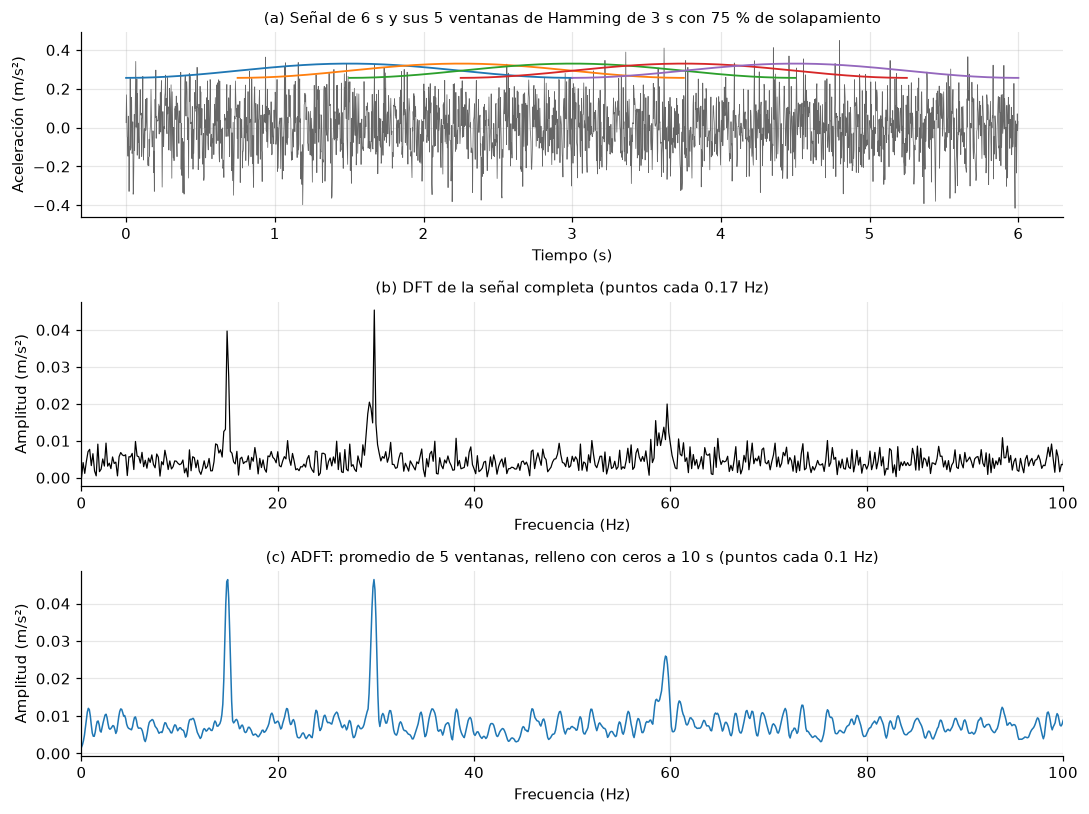

**Figura 2.** DFT de la señal completa frente a ADFT (equivalente a la Fig. 1 del artículo, con una señal sintética). La ADFT es más suave: los picos del motor (15, 30 y 60 Hz) se distinguen mejor del ruido.

In [3]:
def adft(a, fs, win_s=3.0, overlap=0.75, pad_s=10.0):
    # Averaged DFT amplitude spectrum, Eqs. (4)-(6): Hamming windows, overlap and zero padding
    a = a - a.mean()
    n_w = int(round(win_s * fs))
    hop = int(round(n_w * (1 - overlap)))
    n_win = 1 + (a.size - n_w) // hop                       # Eq. (6)
    w = np.hamming(n_w)                                     # Eq. (4)
    n_fft = int(round(pad_s * fs))                          # zero padding to pad_s seconds
    segs = np.stack([a[m * hop:m * hop + n_w] for m in range(n_win)])
    segs = segs - segs.mean(axis=1, keepdims=True)
    amp = np.abs(np.fft.rfft(segs * w, n_fft, axis=1)) * 2 / w.sum()   # amplitude in m/s2
    return np.fft.rfftfreq(n_fft, 1 / fs), amp.mean(axis=0), n_win      # Eq. (5)


def dft_amp(a, fs):
    # Amplitude spectrum of the whole signal, Eqs. (2)-(3)
    a = a - a.mean()
    return np.fft.rfftfreq(a.size, 1 / fs), np.abs(np.fft.rfft(a)) * 2 / a.size


# Synthetic car signal: motor harmonics with small speed fluctuations plus broadband noise
fs_demo, T_demo = 400, 6.0
t_demo = np.arange(0, T_demo, 1 / fs_demo)
wobble = np.cumsum(rng.standard_normal(t_demo.size))
wobble = 0.03 * wobble / np.abs(wobble).max()
phase = 2 * np.pi * 15.0 * np.cumsum(1 + wobble) / fs_demo
a_demo = (0.05 * np.sin(phase) + 0.06 * np.sin(2 * phase + 1.0) + 0.04 * np.sin(4 * phase + 2.0)
          + 0.12 * rng.standard_normal(t_demo.size))

f_full, X_full = dft_amp(a_demo, fs_demo)
f_avg, X_avg, n_win = adft(a_demo, fs_demo)

fig, axes = plt.subplots(3, 1, figsize=(10, 7.5))
ax = axes[0]
ax.plot(t_demo, a_demo, lw=0.5, color="0.4")
hop_s = 3.0 * 0.25
for m in range(n_win):
    tw = np.linspace(m * hop_s, m * hop_s + 3.0, 200)
    ax.plot(tw, 0.25 + 0.08 * np.hamming(200), lw=1.2)
ax.set_xlabel("Tiempo (s)")
ax.set_ylabel("Aceleración (m/s²)")
ax.set_title(f"(a) Señal de {T_demo:.0f} s y sus {n_win} ventanas de Hamming de 3 s con 75 % de solapamiento", fontsize=10)
axes[1].plot(f_full, X_full, lw=0.8, color="k")
axes[1].set_title(f"(b) DFT de la señal completa (puntos cada {1 / T_demo:.2f} Hz)", fontsize=10)
axes[2].plot(f_avg, X_avg, lw=1.0, color="tab:blue")
axes[2].set_title(f"(c) ADFT: promedio de {n_win} ventanas, relleno con ceros a 10 s (puntos cada 0.1 Hz)", fontsize=10)
for ax in axes[1:]:
    ax.set_xlim(0, 100)
    ax.set_xlabel("Frecuencia (Hz)")
    ax.set_ylabel("Amplitud (m/s²)")
fig.tight_layout()
show_figure(fig, 2, "DFT de la señal completa frente a ADFT (equivalente a la Fig. 1 del artículo, con una señal sintética). "
                    "La ADFT es más suave: los picos del motor (15, 30 y 60 Hz) se distinguen mejor del ruido.")

**Interpretación.** Las dos curvas muestran los mismos picos, pero la DFT de la señal completa tiene mucha variación aleatoria entre frecuencias vecinas. La ADFT promedia esa variación y deja una curva suave, que es la que se puede invertir sin crear picos falsos. A cambio, sus picos son más anchos: la ventana de 3 s es la mitad de la señal.

<a id="m-inv"></a>
### 4.3 Diseño y aplicación del filtro inverso

Qué es un filtro inverso y por qué se eligió está en la [ficha 3.3](#c-inv). Aquí se siguen las Ecs. 7–10 del artículo.

**Idea** (Fig. 2 del artículo). Casi todo el contenido en frecuencia de la señal viene del vehículo (velocidad, suspensión, peso, motor) y está tanto fuera como sobre el puente. La frecuencia del puente solo aparece sobre el puente, a veces como un cambio pequeño que no llega a formar un pico visible.

**Paso 1. Prototipo del filtro.** Se invierte el espectro ADFT de fuera del puente, $\bar{X}[k]$ (Ec. 7 del artículo):

$$\tilde{F}[k] = \frac{1}{\bar{X}[k]} \tag{7}$$

El prototipo amplifica las frecuencias de baja amplitud fuera del puente y atenúa los picos del vehículo.

**Paso 2. Escala.** El prototipo tiene unidades de s²/m y valores muy grandes. Se escala con el valor medio del espectro de fuera del puente (Ecs. 8 y 9 del artículo):

$$\bar{\bar{X}} = \frac{1}{N} \sum_{k=0}^{N-1} \bar{X}[k] \tag{8}$$

$$F[k] = \bar{\bar{X}}\;\tilde{F}[k] = \frac{\bar{\bar{X}}}{\bar{X}[k]} \tag{9}$$

donde $\bar{\bar{X}}$ es el promedio del espectro sobre las $N$ frecuencias. El artículo usa el símbolo $\bar{Y}$ en la Ec. 8, el mismo que para el espectro de sobre el puente, pero el texto dice que es el promedio del espectro de **fuera** del puente; aquí se usa $\bar{\bar{X}}$ para evitar la confusión.

**Paso 3. Aplicación.** El filtro multiplica el espectro ADFT de sobre el puente, $\bar{Y}[k]$ (Ec. 10 del artículo):

$$Y_f[k] = F[k]\;\bar{Y}[k] = \bar{\bar{X}}\;\frac{\bar{Y}[k]}{\bar{X}[k]} \tag{10}$$

**Por qué funciona.** Si la vibración del vehículo es su "filtro" propio $H_v$ aplicado a una excitación $E$ (motor, rugosidad), fuera del puente $\bar{X} \approx |H_v|\,E$ y sobre el puente $\bar{Y} \approx |H_v|\,(E + B)$, donde $B$ es el aporte del puente. Entonces:

$$\frac{\bar{Y}[k]}{\bar{X}[k]} \approx 1 + \frac{B[k]}{E[k]} \tag{11}$$

Lo que comparten las dos señales se cancela y queda $\approx 1$; donde está el puente, el cociente crece. La escala $\bar{\bar{X}}$ es una constante: cambia la altura de la curva, **no** la posición de los picos.

El código reproduce el ejemplo hipotético de las Figs. 2–4 del artículo.

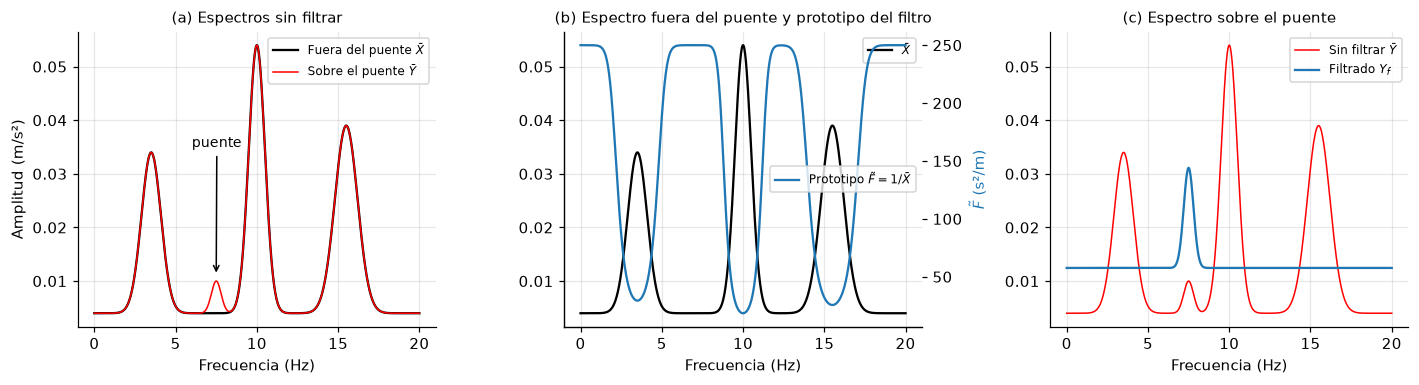

**Figura 3.** Ejemplo hipotético del filtro inverso (equivalente a las Figs. 2–4 del artículo). El aporte del puente a 7.5 Hz es casi invisible sin filtrar (a); el prototipo es alto donde el vehículo tiene poca energía (b); al filtrar, el puente queda como el pico dominante (c).

In [4]:
def bumps(f, centers, heights, widths):
    # Sum of Gaussian-shaped peaks, used to draw hypothetical spectra
    return sum(h * np.exp(-0.5 * ((f - c) / w)**2) for c, h, w in zip(centers, heights, widths))


f_h = np.linspace(0, 20, 801)
X_h = 0.004 + bumps(f_h, [3.5, 10.0, 15.5], [0.030, 0.050, 0.035], [0.6, 0.5, 0.7])   # off-bridge
Y_h = X_h + bumps(f_h, [7.5], [0.006], [0.3])                                           # on-bridge
F_proto = 1 / X_h                          # Eq. (7)
F_h = X_h.mean() * F_proto                 # Eqs. (8)-(9)
Yf_h = F_h * Y_h                           # Eq. (10)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
axes[0].plot(f_h, X_h, "k", label="Fuera del puente $\\bar{X}$")
axes[0].plot(f_h, Y_h, "r", lw=1, label="Sobre el puente $\\bar{Y}$")
axes[0].annotate("puente", (7.5, 0.011), (6.0, 0.035), arrowprops=dict(arrowstyle="->"), fontsize=9)
axes[0].set_title("(a) Espectros sin filtrar", fontsize=10)
axes[1].plot(f_h, X_h, "k", label="$\\bar{X}$")
ax2 = axes[1].twinx()
ax2.plot(f_h, F_proto, "tab:blue", label="Prototipo $\\tilde{F} = 1/\\bar{X}$")
ax2.set_ylabel("$\\tilde{F}$ (s²/m)", color="tab:blue")
ax2.grid(False)
axes[1].set_title("(b) Espectro fuera del puente y prototipo del filtro", fontsize=10)
axes[2].plot(f_h, Y_h, "r", lw=1, label="Sin filtrar $\\bar{Y}$")
axes[2].plot(f_h, Yf_h, "tab:blue", label="Filtrado $Y_f$")
axes[2].set_title("(c) Espectro sobre el puente", fontsize=10)
for ax in axes:
    ax.set_xlabel("Frecuencia (Hz)")
    ax.legend(fontsize=8, loc="upper right")
axes[0].set_ylabel("Amplitud (m/s²)")
ax2.legend(fontsize=8, loc="center right")
fig.tight_layout()
show_figure(fig, 3, "Ejemplo hipotético del filtro inverso (equivalente a las Figs. 2–4 del artículo). El aporte del puente "
                    "a 7.5 Hz es casi invisible sin filtrar (a); el prototipo es alto donde el vehículo tiene poca energía (b); "
                    "al filtrar, el puente queda como el pico dominante (c).")

**Interpretación.** Sin filtrar, el pico más alto es el del vehículo a 10 Hz y el aporte del puente es un pequeño escalón. Después de filtrar, los picos del vehículo quedan aplanados al nivel medio y el puente a 7.5 Hz pasa a ser, por mucho, el pico dominante. Esto funciona porque, en este ejemplo, el espectro de fuera del puente es **exactamente** la parte del vehículo del espectro de sobre el puente. En un ensayo real eso solo se cumple de forma aproximada.

La Figura 4 resume el método completo (Fig. 5 del artículo).

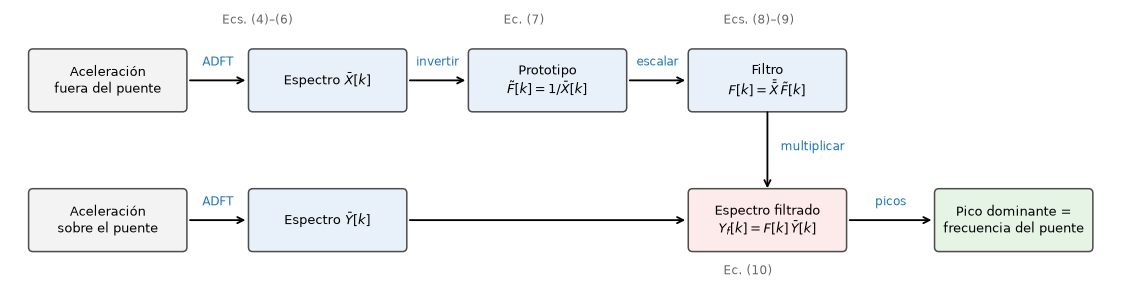

**Figura 4.** Diagrama de flujo del método de filtrado inverso (esquema propio basado en la Fig. 5 del artículo).

In [5]:
def box(ax, xy, text, color="#e8f0fa", w=1.7, h=0.62):
    ax.add_patch(FancyBboxPatch((xy[0] - w / 2, xy[1] - h / 2), w, h, boxstyle="round,pad=0.05",
                                fc=color, ec="0.3"))
    ax.text(xy[0], xy[1], text, ha="center", va="center", fontsize=8.5)


def arrow(ax, p0, p1, label=None):
    ax.annotate("", p1, p0, arrowprops=dict(arrowstyle="->", lw=1.2))
    if label:
        ax.text((p0[0] + p1[0]) / 2, (p0[1] + p1[1]) / 2 + 0.17, label, ha="center", fontsize=8, color="tab:blue")


fig, ax = plt.subplots(figsize=(13, 3.3))
top, bot = 1.6, 0.0
box(ax, (0.9, top), "Aceleración\nfuera del puente", "#f3f3f3")
box(ax, (3.4, top), "Espectro $\\bar{X}[k]$")
box(ax, (5.9, top), "Prototipo\n$\\tilde{F}[k] = 1/\\bar{X}[k]$")
box(ax, (8.4, top), "Filtro\n$F[k] = \\bar{\\bar{X}}\\,\\tilde{F}[k]$")
box(ax, (0.9, bot), "Aceleración\nsobre el puente", "#f3f3f3")
box(ax, (3.4, bot), "Espectro $\\bar{Y}[k]$")
box(ax, (8.4, bot), "Espectro filtrado\n$Y_f[k] = F[k]\\,\\bar{Y}[k]$", "#fdeaea")
box(ax, (11.2, bot), "Pico dominante =\nfrecuencia del puente", "#e6f4e6")
arrow(ax, (1.8, top), (2.5, top), "ADFT")
arrow(ax, (4.3, top), (5.0, top), "invertir")
arrow(ax, (6.8, top), (7.5, top), "escalar")
arrow(ax, (1.8, bot), (2.5, bot), "ADFT")
arrow(ax, (4.3, bot), (7.5, bot), "")
arrow(ax, (8.4, top - 0.33), (8.4, bot + 0.33), "")
arrow(ax, (9.3, bot), (10.3, bot), "picos")
ax.text(8.55, 0.8, "multiplicar", fontsize=8, color="tab:blue")
ax.text(2.2, 2.25, "Ecs. (4)–(6)", fontsize=8, color="0.4")
ax.text(5.4, 2.25, "Ec. (7)", fontsize=8, color="0.4")
ax.text(7.9, 2.25, "Ecs. (8)–(9)", fontsize=8, color="0.4")
ax.text(7.9, -0.62, "Ec. (10)", fontsize=8, color="0.4")
ax.set_xlim(-0.2, 12.4)
ax.set_ylim(-0.8, 2.4)
ax.axis("off")
show_figure(fig, 4, "Diagrama de flujo del método de filtrado inverso (esquema propio basado en la Fig. 5 del artículo).")

<a id="m-score"></a>
### 4.4 Puntuación de picos

Qué es la prominencia está en la [ficha 3.4](#c-prom). Para medir si el filtro ayuda, los autores califican cada pico del espectro de 0 a 20 Hz con dos puntajes, ambos escalados a 100 (Sección 4.3 del artículo): uno por su **amplitud** y otro por su **prominencia**. Luego promedian los puntajes de todos los cruces y los muestran como un histograma por frecuencia (Figs. 20 y 21 del artículo).

El artículo no dice cómo combina los dos puntajes ni el ancho de los intervalos del histograma. Aquí se usa el promedio de ambos y, como en sus figuras, intervalos de 0.8 Hz:

$$S_i = \frac{1}{2}\left(100\,\frac{A_i}{\max_j A_j} + 100\,\frac{P_i}{\max_j P_j}\right) \tag{12}$$

donde $A_i$ y $P_i$ son la amplitud y la prominencia del pico $i$, y el máximo se toma entre todos los picos $j$ del mismo espectro. El pico con $S_i = 100$ es a la vez el más alto y el más prominente. En cada intervalo de frecuencia se guarda el mayor puntaje y luego se promedia entre cruces.

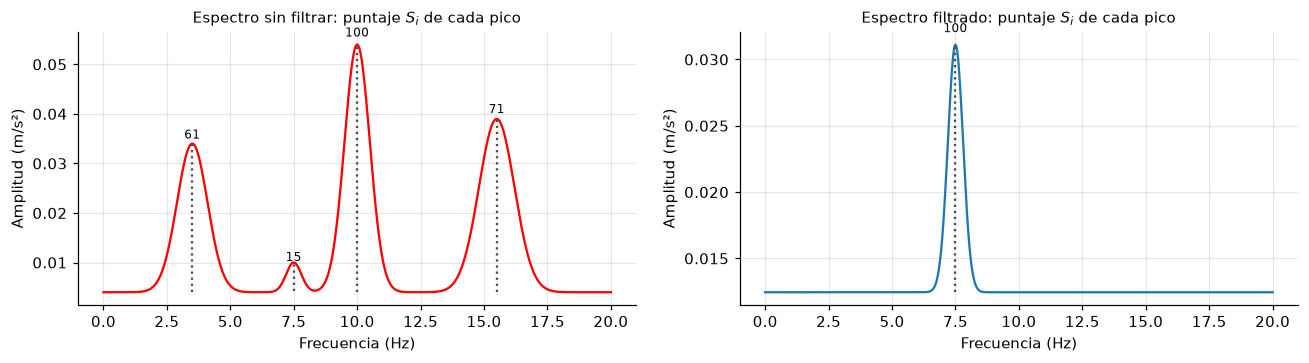

**Figura 5.** Puntuación de picos, Ec. (12), aplicada al ejemplo hipotético de la Figura 3. Las líneas punteadas muestran la prominencia de cada pico y los números su puntaje.

In [6]:
F_MIN, F_MAX = 0.5, 20.0            # band analysed (Hz)
BIN_W = 0.8                         # histogram bin width (Hz), read from Figs. 20-21
EDGES = np.arange(0, F_MAX + BIN_W / 2, BIN_W)


def peak_scores(f, s, f_min=F_MIN, f_max=F_MAX):
    # Score of every peak in the band, Eq. (12)
    sel = (f >= f_min) & (f <= f_max)
    fb, sb = f[sel], s[sel]
    idx, _ = find_peaks(sb)
    amp = sb[idx]
    prom = peak_prominences(sb, idx)[0]
    score = 50 * amp / amp.max() + 50 * prom / prom.max()
    return fb[idx], amp, prom, score


def binned_scores(f_pk, score):
    # Highest score in each frequency bin of the histogram
    out = np.zeros(EDGES.size - 1)
    for b, sc in zip(np.digitize(f_pk, EDGES) - 1, score):
        if 0 <= b < out.size:
            out[b] = max(out[b], sc)
    return out


def top_peak(f, s):
    # Frequency of the best-scored peak
    f_pk, _, _, sc = peak_scores(f, s)
    return f_pk[np.argmax(sc)]


fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for ax, s, name, col in ((axes[0], Y_h, "sin filtrar", "r"), (axes[1], Yf_h, "filtrado", "tab:blue")):
    f_pk, amp, prom, sc = peak_scores(f_h, s)
    ax.plot(f_h, s, color=col)
    for fp, a_, p_, s_ in zip(f_pk, amp, prom, sc):
        if p_ < 0.01 * prom.max():
            continue                       # skip numerical ripples of the flat parts
        ax.vlines(fp, a_ - p_, a_, color="0.3", ls=":")
        ax.text(fp, a_ * 1.03, f"{s_:.0f}", ha="center", fontsize=8)
    ax.set_title(f"Espectro {name}: puntaje $S_i$ de cada pico", fontsize=10)
    ax.set_xlabel("Frecuencia (Hz)")
    ax.set_ylabel("Amplitud (m/s²)")
fig.tight_layout()
show_figure(fig, 5, "Puntuación de picos, Ec. (12), aplicada al ejemplo hipotético de la Figura 3. Las líneas punteadas "
                    "muestran la prominencia de cada pico y los números su puntaje.")

**Interpretación.** Sin filtrar, el puente a 7.5 Hz forma un pico pequeño con apenas 15 puntos; los 100 puntos los tiene el vehículo a 10 Hz. Después de filtrar, el puente es el único pico: obtiene los 100 puntos.

<a id="procedimiento"></a>
## 5. Procedimiento

El artículo valida el método con un ensayo de laboratorio (Secciones 3 y 4). Aquí se describe ese ensayo y se reproduce con una simulación propia, porque sus datos no son públicos.

<a id="p-puente"></a>
### 5.1 Puente de laboratorio

Una placa de acero laminado en caliente (tipo W44) simplemente apoyada, con un apoyo articulado y uno de rodillo (Figs. 6 y 7 del artículo). Antes y después del tramo principal hay tramos de aproximación y salida para que el auto llegue a velocidad constante y frene fuera del puente.

La frecuencia natural de una viga simplemente apoyada es:

$$f_n = \frac{n^2 \pi}{2L^2}\sqrt{\frac{EI}{\bar{m}}}, \qquad I = \frac{b\,h^3}{12} \tag{13}$$

donde $n$ es el número de modo, $L$ la luz, $b$ el ancho y $h$ el espesor de la placa, y $\bar{m}$ la masa por unidad de longitud. El artículo no reporta el valor numérico de la frecuencia del puente; solo la marca con una línea en sus Figs. 18–21, cerca de 7.6 Hz. La Ec. (13) con los datos reportados da ese mismo valor.

In [7]:
L = 2.0                    # span (m)
WIDTH, THICK = 0.330, 0.0127
E_STEEL = 200e9            # Pa
MASS_PLATE = 60.0          # kg, reported weight of the plate
M_BAR = MASS_PLATE / L     # kg/m
I_SEC = WIDTH * THICK**3 / 12
EI = E_STEEL * I_SEC
N_MODES = 4
n_idx = np.arange(1, N_MODES + 1)
OMEGA_B = (n_idx * np.pi / L)**2 * np.sqrt(EI / M_BAR)      # rad/s, Eq. (13)
F_B = OMEGA_B / (2 * np.pi)
F_BRIDGE = F_B[0]

show_table(pd.DataFrame({
    "Propiedad": ["Luz L", "Ancho b", "Espesor h", "Módulo de elasticidad E", "Fluencia / rotura",
                  "Masa de la placa", "Masa por unidad de longitud", "Momento de inercia I", "Rigidez EI"],
    "Valor": ["2 m", "330 mm", "12.7 mm", "200 GPa", "250 / 310 MPa", "60 kg",
              f"{M_BAR:.0f} kg/m", f"{I_SEC:.3g} m⁴", f"{EI:,.0f} N·m²"],
    "Origen": ["Reportado"] * 6 + ["Calculado"] * 3}),
    1, "Propiedades del puente de laboratorio.", hide_index=True)

show_table(pd.DataFrame({"Modo": n_idx, "Frecuencia (Hz)": F_B}), 2,
           "Frecuencias naturales del puente vacío, Ec. (13).", hide_index=True)

**Tabla 1.** Propiedades del puente de laboratorio.

Propiedad,Valor,Origen
Luz L,2 m,Reportado
Ancho b,330 mm,Reportado
Espesor h,12.7 mm,Reportado
Módulo de elasticidad E,200 GPa,Reportado
Fluencia / rotura,250 / 310 MPa,Reportado
Masa de la placa,60 kg,Reportado
Masa por unidad de longitud,30 kg/m,Calculado
Momento de inercia I,5.63e-08 m⁴,Calculado
Rigidez EI,"11,266 N·m²",Calculado


**Tabla 2.** Frecuencias naturales del puente vacío, Ec. (13).

Modo,Frecuencia (Hz)
1,7.61
2,30.44
3,68.49
4,121.76


**Lectura.** $f_1 \approx 7.6$ Hz coincide con la línea de las Figs. 18–21 del artículo, que los autores obtuvieron con un ensayo de vibración libre. Los demás modos (30 Hz y más) quedan fuera del rango 0–20 Hz que analiza el artículo.

<a id="p-auto"></a>
### 5.2 Auto robot

El vehículo es un auto robot construido por los autores (Fig. 8 del artículo): dos placas de aluminio de 350 × 125 mm unidas por cuatro varillas con resortes, que hacen de suspensión. Cada rueda tiene su motor. El teléfono y el sensor van en la placa superior.

**Combinaciones ensayadas.** 3 tipos de resorte × 3 velocidades = **9 casos**.

**Frecuencias del auto.** La frecuencia de la suspensión (rebote de la placa superior) es:

$$f_v = \frac{1}{2\pi}\sqrt{\frac{k_s}{m_s}} \tag{14}$$

donde $k_s$ es la rigidez total de la suspensión y $m_s$ la masa suspendida. El artículo **no reporta** esta frecuencia, y su texto no aclara si 425, 615 y 726 N/m es la rigidez de **cada** resorte o la del conjunto. Con 4 resortes en paralelo, el auto vibraría a 6.6–8.6 Hz, justo alrededor de la frecuencia del puente; con la rigidez total, a 3.3–4.3 Hz (Tabla 4). La simulación usa la segunda lectura y la [sección 6.5](#r-sens) prueba la primera.

**Picos del motor.** Los picos principales de fuera del puente dependen de la velocidad (Sección 4.1 del artículo). En la Fig. 12 del artículo aparecen cerca de 10, 15 y 21 Hz para 0.2, 0.3 y 0.4 m/s, más sus armónicos:

$$f_m \approx c_m\, v, \qquad c_m \approx 52\ \text{Hz por m/s} \tag{15}$$

In [8]:
M_S, M_U = 1.0, 1.3                        # sprung (top plate) and unsprung mass (kg)
K_SPRING = {"A": 425.0, "B": 615.0, "C": 726.0}
SPEEDS = [0.2, 0.3, 0.4]                   # m/s
C_MOTOR = 52.0                             # Hz per m/s, read from Fig. 12

show_table(pd.DataFrame({
    "Parámetro": ["Masa total", "Placa superior (con teléfono y sensor)", "Placa inferior, motores y ruedas",
                  "Rigidez de los resortes A / B / C", "Velocidades", "Relación de masas auto / puente",
                  "Frecuencia del motor"],
    "Valor": ["2.3 kg", "1.0 kg", "1.3 kg", "425 / 615 / 726 N/m", "0.2 / 0.3 / 0.4 m/s",
              f"{(M_S + M_U) / MASS_PLATE * 100:.1f} %", f"≈ {C_MOTOR:.0f}·v Hz"],
    "Origen": ["Reportado"] * 6 + ["Leído de la Fig. 12"]}),
    3, "Parámetros del auto robot.", hide_index=True)

rows = []
for name, k in K_SPRING.items():
    rows.append({"Resorte": name, "k (N/m)": k,
                 "f_v con k total (Hz)": np.sqrt(k / M_S) / (2 * np.pi),
                 "f_v con 4 resortes en paralelo (Hz)": np.sqrt(4 * k / M_S) / (2 * np.pi)})
show_table(pd.DataFrame(rows), 4, "Frecuencia de la suspensión, Ec. (14), con las dos lecturas posibles de la rigidez. "
           f"Frecuencia del puente: {F_BRIDGE:.2f} Hz.", hide_index=True)
show_table(pd.DataFrame({"Velocidad (m/s)": SPEEDS,
                         "f_m (Hz)": [C_MOTOR * v for v in SPEEDS],
                         "2 f_m (Hz)": [2 * C_MOTOR * v for v in SPEEDS],
                         "Duración sobre el puente (s)": [L / v for v in SPEEDS]}),
           5, "Frecuencia del motor, Ec. (15), y duración del cruce de 2 m.", hide_index=True)

**Tabla 3.** Parámetros del auto robot.

Parámetro,Valor,Origen
Masa total,2.3 kg,Reportado
Placa superior (con teléfono y sensor),1.0 kg,Reportado
"Placa inferior, motores y ruedas",1.3 kg,Reportado
Rigidez de los resortes A / B / C,425 / 615 / 726 N/m,Reportado
Velocidades,0.2 / 0.3 / 0.4 m/s,Reportado
Relación de masas auto / puente,3.8 %,Reportado
Frecuencia del motor,≈ 52·v Hz,Leído de la Fig. 12


**Tabla 4.** Frecuencia de la suspensión, Ec. (14), con las dos lecturas posibles de la rigidez. Frecuencia del puente: 7.61 Hz.

Resorte,k (N/m),f_v con k total (Hz),f_v con 4 resortes en paralelo (Hz)
A,425.00,3.28,6.56
B,615.00,3.95,7.89
C,726.00,4.29,8.58


**Tabla 5.** Frecuencia del motor, Ec. (15), y duración del cruce de 2 m.

Velocidad (m/s),f_m (Hz),2 f_m (Hz),Duración sobre el puente (s)
0.20,10.40,20.80,10.00
0.30,15.60,31.20,6.67
0.40,20.80,41.60,5.00


**Lectura.**

- **Relación de masas.** La del ensayo (3.8 %) es mayor que la de un puente real con un auto. Los autores lo justifican porque en un puente real suelen cruzar varios vehículos a la vez. Una consecuencia: la masa del auto baja la frecuencia del conjunto auto–puente por debajo de la del puente vacío.
- **Motor.** A 0.2 m/s el motor vibra a ≈ 10 Hz, cerca del puente (7.6 Hz). A 0.4 m/s su pico principal (≈ 21 Hz) queda fuera del rango 0–20 Hz.
- **Duración.** A 0.4 m/s el auto cruza en 5 s: con ventanas de 3 s y 75 % de solapamiento solo hay 3 ventanas para promediar. El artículo reporta señales de 4–8 s.

<a id="p-instr"></a>
### 5.3 Instrumentos: sensor y teléfono

- **Teléfono:** Samsung Galaxy S8 en la placa superior, con una aplicación del grupo de los autores que registra la aceleración **vertical global** a **400 Hz** y corrige la frecuencia de muestreo.
- **Sensor de referencia:** acelerómetro inalámbrico G-Link-200 junto al teléfono, a **512 Hz**.
- **Remuestreo.** Los intervalos entre muestras del teléfono no son exactamente constantes (*jitter*); antes de la ADFT, la señal se remuestrea por interpolación a 400 Hz exactos.
- **Diferencias entre dispositivos.** Las señales del teléfono y del sensor difieren por la posición del acelerómetro dentro del teléfono y por la vibración del propio teléfono sobre la placa (Fig. 10 del artículo).

La simulación representa estas diferencias así (valores supuestos): el sensor tiene poco ruido y muestreo exacto; el teléfono tiene más ruido, *jitter* en el muestreo y una pequeña resonancia de montaje a 35 Hz, porque el teléfono no está unido de forma perfectamente rígida.

In [9]:
SENSOR_FS, PHONE_FS = 512, 400
SENSOR_NOISE, PHONE_NOISE = 0.003, 0.012     # m/s2 rms (assumed)
PHONE_JITTER = 0.15                          # std of sample interval / nominal interval (assumed)
F_MOUNT, ZETA_MOUNT = 35.0, 0.10             # phone mounting resonance (assumed)


def measure_sensor(t, a, rng):
    # Reference accelerometer: exact sampling plus small noise
    ts = np.arange(0, t[-1], 1 / SENSOR_FS)
    return np.interp(ts, t, a) + SENSOR_NOISE * rng.standard_normal(ts.size)


def measure_phone(t, a, rng):
    # Smartphone: irregular sampling (jitter), more noise, then resampled to a uniform 400 Hz grid
    dt = (1 / PHONE_FS) * (1.01 + PHONE_JITTER * rng.standard_normal(int(t[-1] * PHONE_FS * 1.2)))
    ts = np.cumsum(np.clip(dt, 1e-4, None))
    ts = ts[ts < t[-1]]
    raw = np.interp(ts, t, a) + PHONE_NOISE * rng.standard_normal(ts.size)
    t_uniform = np.arange(0, ts[-1], 1 / PHONE_FS)
    return np.interp(t_uniform, ts, raw)

<a id="p-sim"></a>
### 5.4 Simulación de los ensayos

**Qué se simula.** Cada recorrido del auto, fuera del puente y sobre él, con un modelo de interacción vehículo–puente más completo que la Ec. (1). Es un modelo propio: el artículo no tiene modelo numérico.

**Puente** (superposición modal con los 4 modos de la Tabla 2). Cada modo $n$ tiene coordenada $q_n(t)$ y forma $\phi_n(x) = \sqrt{2/(\bar{m}L)}\,\sin(n\pi x/L)$:

$$\ddot{q}_n + 2\zeta_b\,\omega_n\,\dot{q}_n + \omega_n^2\, q_n = -\sum_{a=1}^{2} \phi_n(x_a)\, R_a \tag{16}$$

donde $\omega_n = 2\pi f_n$, $\zeta_b$ es el amortiguamiento del puente, $x_a$ la posición del eje $a$ (delantero o trasero) y $R_a$ la fuerza que ese eje aplica sobre el puente.

**Auto** (dos ejes, rebote de la placa superior). Las ruedas siguen la superficie: el desplazamiento bajo el eje $a$ es $z_a = \sum_n \phi_n(x_a)\,q_n + r(x_a)$, con $r(x)$ la rugosidad. La placa superior se mueve con:

$$m_s\,\ddot{y}_s = -k_s\,(y_s - \bar{z}) - c_s\,(\dot{y}_s - \dot{\bar{z}}) + F_m(t), \qquad \bar{z} = \tfrac{1}{2}(z_1 + z_2) \tag{17}$$

$$R_a = \tfrac{1}{2}\Big[(m_s + m_u)\,g + m_u\,\ddot{z}_a + m_s\,\ddot{y}_s + F_u(t)\Big] \tag{18}$$

donde $y_s$ es el desplazamiento de la placa superior, $c_s$ el amortiguamiento de la suspensión, $g$ la gravedad, $F_m$ la vibración del motor que llega a la placa superior y $F_u$ la que los motores aplican directamente sobre la superficie a través de las ruedas. La aceleración que miden el teléfono y el sensor es $\ddot{y}_s$.

**Fuentes de vibración.** Son las que el artículo menciona de forma cualitativa; sus valores son supuestos (Tabla 6).

- **Motor:** armónicos 1, 2 y 4 de $f_m$ (Ec. 15) con pequeñas variaciones de velocidad, con amplitudes al azar en cada caso.
- **Ruedas:** fuerza aleatoria de banda ancha. Sobre el suelo no mueve al auto, porque el suelo no cede; sobre el puente lo hace vibrar, y esa vibración vuelve al auto.
- **Superficie:** rugosidad aleatoria y una pequeña junta (escalón suave) en la entrada, iguales en estadística fuera y sobre el puente.
- **Velocidad:** el artículo explica que la deformación del puente frena un poco al auto. Aquí la velocidad sobre el puente es 1 % menor que fuera de él.

**Ensayos simulados por caso:** 4 recorridos fuera del puente (3 para diseñar el filtro y 1 nuevo para verificarlo, como en la Sección 4.2 del artículo) y 5 cruces del puente. El artículo no dice cuántos cruces hizo.

In [10]:
ZETA_B = 0.005                 # bridge damping ratio (assumed)
ZETA_S = 0.03                  # suspension damping ratio (assumed)
D_AXLE = 0.25                  # axle spacing (m, assumed)
X_START = -0.5                 # front axle starts 0.5 m before the bridge (approach span)
ROUGH_STD = 16e-6              # surface roughness std (m, assumed)
JOINT_H, JOINT_L = 0.3e-3, 0.02   # entry joint height and length (m, assumed)
WHEEL_FORCE = 0.5              # broadband motor force at the wheels (N rms, assumed)
HARMONICS = np.array([1, 2, 4])
FS_SIM = 2048                  # integration rate (Hz)
G = 9.81
PHI_AMP = np.sqrt(2 / (M_BAR * L))

show_table(pd.DataFrame({
    "Supuesto": ["Amortiguamiento del puente", "Amortiguamiento de la suspensión", "Separación entre ejes",
                 "Rugosidad de la superficie (desv. estándar)", "Junta de entrada (altura × largo)",
                 "Fuerza de banda ancha en las ruedas", "Amplitud de los armónicos del motor a 0.3 m/s",
                 "Velocidad sobre el puente", "Ruido sensor / teléfono", "Resonancia de montaje del teléfono"],
    "Valor": [f"{ZETA_B * 100:.1f} %", f"{ZETA_S * 100:.0f} %", f"{D_AXLE:.2f} m", f"{ROUGH_STD * 1e6:.0f} µm",
              f"{JOINT_H * 1e3:.1f} mm × {JOINT_L * 1e3:.0f} mm", f"{WHEEL_FORCE} N", "0.05–0.14 m/s² (al azar)",
              "1 % menor que fuera", f"{SENSOR_NOISE} / {PHONE_NOISE} m/s²", f"{F_MOUNT:.0f} Hz"]}),
    6, "Parámetros supuestos de la simulación (el artículo no los reporta).", hide_index=True)


def phi(x):
    # Mass-normalised mode shapes at positions x, shape (runs, modes)
    return PHI_AMP * np.sin(np.outer(x, n_idx) * np.pi / L)


def dphi(x):
    # Slopes of the mode shapes
    return PHI_AMP * (n_idx * np.pi / L) * np.cos(np.outer(x, n_idx) * np.pi / L)


def surface_profile(rng, rough_scale=1.0, dx=2e-4, length=3.5):
    # Random roughness (PSD ~ n^-2) plus a smooth entry joint; returns r, dr/dx and d2r/dx2
    n = int(length / dx)
    k = np.fft.rfftfreq(n, dx)
    amp = np.zeros_like(k)
    ok = (k > 0.5) & (k < 400)
    amp[ok] = 1 / k[ok]
    spec = amp * np.exp(2j * np.pi * rng.random(k.size))
    r0 = np.fft.irfft(spec, n)
    scale = rough_scale * ROUGH_STD / r0.std()
    r = r0 * scale
    r1 = np.fft.irfft(spec * 2j * np.pi * k, n) * scale
    r2 = np.fft.irfft(spec * -(2 * np.pi * k)**2, n) * scale
    x = X_START - D_AXLE + np.arange(n) * dx
    j = (x >= 0) & (x <= JOINT_L)
    w = 2 * np.pi / JOINT_L
    r[j] += JOINT_H / 2 * (1 - np.cos(w * x[j]))
    r1[j] += JOINT_H / 2 * w * np.sin(w * x[j])
    r2[j] += JOINT_H / 2 * w**2 * np.cos(w * x[j])
    return x, r, r1, r2


def motor_force(t, v, amps, rng):
    # Motor harmonics with slow speed fluctuations (+-1.2 %) acting on the top plate
    eps = np.cumsum(rng.standard_normal(t.size))
    eps = eps - np.linspace(eps[0], eps[-1], t.size)
    eps = 0.012 * eps / np.abs(eps).max()
    ph = 2 * np.pi * C_MOTOR * v * np.cumsum(1 + eps) * (t[1] - t[0])
    return sum(M_S * a * np.sin(h * ph + 2 * np.pi * rng.random()) for h, a in zip(HARMONICS, amps))


def simulate(runs):
    # Vectorised RK4 simulation of all runs; returns (t, sprung acc, phone acc) while the front axle is on the 2 m plate
    R = len(runs)
    v = np.array([r["v"] for r in runs])
    k_s = np.array([r["k_s"] for r in runs])
    c_s = 2 * ZETA_S * np.sqrt(k_s * M_S)
    on = np.array([r["on"] for r in runs], float)
    dt = 1 / FS_SIM
    ns = int(np.ceil(((L - X_START) / v).max() / dt)) + 1
    th = np.arange(2 * ns + 2) * dt / 2                      # half-step time grid
    rr, rd, rdd = (np.zeros((2, R, th.size)) for _ in range(3))
    Fm, Fu = np.zeros((R, th.size)), np.zeros((R, th.size))
    for i, r in enumerate(runs):
        g = np.random.default_rng(r["seed"])
        xg, p0, p1, p2 = surface_profile(g, r.get("rough", 1.0))
        for ax_i, offset in enumerate((0.0, D_AXLE)):
            xt = X_START - offset + v[i] * th
            rr[ax_i, i] = np.interp(xt, xg, p0)
            rd[ax_i, i] = v[i] * np.interp(xt, xg, p1)
            rdd[ax_i, i] = v[i]**2 * np.interp(xt, xg, p2)
        Fm[i] = motor_force(th, v[i], r["amps"], g)
        wn = g.standard_normal(th.size)
        wn = np.fft.irfft(np.fft.rfft(wn) * (np.fft.rfftfreq(th.size, dt / 2) < 100), th.size)
        Fu[i] = WHEEL_FORCE * wn / wn.std()
    wp = 2 * np.pi * F_MOUNT
    mu2 = M_U / 2

    def rhs(j, s):
        q, qd, y, yd, p, pd = s
        x_front = X_START + v * th[j]
        PH, zc, zcd = [], 0.0, 0.0
        for ax_i, offset in enumerate((0.0, D_AXLE)):
            x = x_front - offset
            on_b = on * ((x >= 0) & (x <= L))
            ph = phi(np.clip(x, 0, L)) * on_b[:, None]
            dph = dphi(np.clip(x, 0, L)) * on_b[:, None]
            PH.append(ph)
            zc = zc + 0.5 * ((ph * q).sum(1) + rr[ax_i, :, j])
            zcd = zcd + 0.5 * ((ph * qd).sum(1) + v * (dph * q).sum(1) + rd[ax_i, :, j])
        ydd = (-k_s * (y - zc) - c_s * (yd - zcd) + Fm[:, j]) / M_S              # Eq. (17)
        b = -2 * ZETA_B * OMEGA_B * qd - OMEGA_B**2 * q
        for ax_i in range(2):                                                    # Eqs. (16) and (18)
            b = b - PH[ax_i] * ((M_U + M_S) / 2 * G + mu2 * rdd[ax_i, :, j] + M_S / 2 * ydd + Fu[:, j] / 2)[:, None]
        # Unsprung inertia couples q'' through both axles: solve (I + mu2 * Phi Phi^T) q'' = b (Woodbury, 2x2)
        pf, pr = PH
        c11 = 1 / mu2 + (pf * pf).sum(1)
        c22 = 1 / mu2 + (pr * pr).sum(1)
        c12 = (pf * pr).sum(1)
        u1, u2 = (pf * b).sum(1), (pr * b).sum(1)
        det = c11 * c22 - c12**2
        qdd = b - pf * ((c22 * u1 - c12 * u2) / det)[:, None] - pr * ((c11 * u2 - c12 * u1) / det)[:, None]
        pdd = -wp**2 * (p - y) - 2 * ZETA_MOUNT * wp * (pd - yd)                 # phone on its mount
        return [qd, qdd, yd, ydd, pd, pdd]

    s = [np.zeros((R, N_MODES)), np.zeros((R, N_MODES))] + [np.zeros(R) for _ in range(4)]
    acc, acc_phone = np.zeros((R, ns)), np.zeros((R, ns))
    for i in range(ns):
        j = 2 * i
        k1 = rhs(j, s)
        acc[:, i], acc_phone[:, i] = k1[3], k1[5]
        k2 = rhs(j + 1, [a + dt / 2 * b for a, b in zip(s, k1)])
        k3 = rhs(j + 1, [a + dt / 2 * b for a, b in zip(s, k2)])
        k4 = rhs(j + 2, [a + dt * b for a, b in zip(s, k3)])
        s = [a + dt / 6 * (b + 2 * c + 2 * d + e) for a, b, c, d, e in zip(s, k1, k2, k3, k4)]
    t = np.arange(ns) * dt
    out = []
    for i in range(R):
        t0, t1 = -X_START / v[i], (L - X_START) / v[i]
        m = (t >= t0) & (t <= t1)
        out.append((t[m] - t0, acc[i, m], acc_phone[i, m]))
    return out

**Tabla 6.** Parámetros supuestos de la simulación (el artículo no los reporta).

Supuesto,Valor
Amortiguamiento del puente,0.5 %
Amortiguamiento de la suspensión,3 %
Separación entre ejes,0.25 m
Rugosidad de la superficie (desv. estándar),16 µm
Junta de entrada (altura × largo),0.3 mm × 20 mm
Fuerza de banda ancha en las ruedas,0.5 N
Amplitud de los armónicos del motor a 0.3 m/s,0.05–0.14 m/s² (al azar)
Velocidad sobre el puente,1 % menor que fuera
Ruido sensor / teléfono,0.003 / 0.012 m/s²
Resonancia de montaje del teléfono,35 Hz


In [11]:
N_OFF, N_ON = 4, 5             # off-bridge runs (3 design + 1 verification) and bridge crossings per case
SPEED_DROP = 0.01              # speed reduction on the bridge


def make_runs(n_off, n_on, seed0, k_factor=1.0, speed_drop=SPEED_DROP, rough_on=1.0, speeds=SPEEDS):
    # Build the list of runs for all speed x spring cases
    runs, seed = [], seed0
    g = np.random.default_rng(SEED)          # same motor amplitudes for a case in every batch
    for v in speeds:
        for sp, k in K_SPRING.items():
            amps = (v / 0.3) * np.array([0.08, 0.10, 0.04]) * g.uniform(0.6, 1.4, 3)
            for kind, n, vv, rough in (("off", n_off, v, 1.0), ("on", n_on, v * (1 - speed_drop), rough_on)):
                for _ in range(n):
                    runs.append(dict(v=vv, k_s=k_factor * k, on=kind == "on", amps=amps, seed=seed,
                                     rough=rough, case=(v, sp), kind=kind))
                    seed += 1
    return runs


t0 = time.time()
runs = make_runs(N_OFF, N_ON, seed0=1000)
signals = simulate(runs)
print(f"{len(runs)} runs simulated in {time.time() - t0:.1f} s")

81 runs simulated in 14.2 s


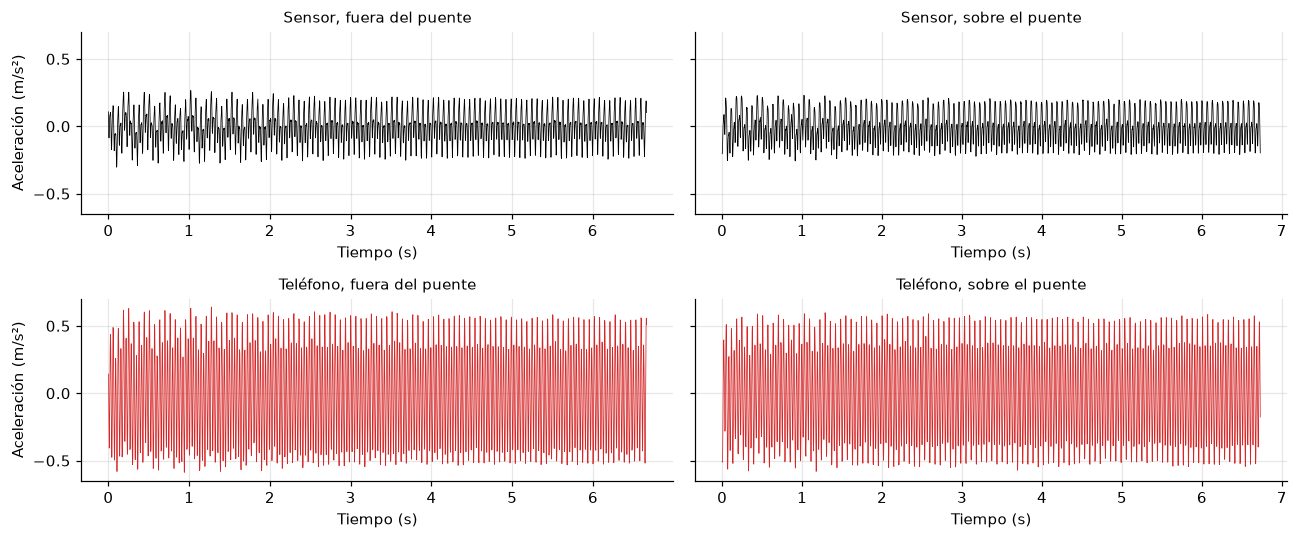

**Figura 6.** Aceleraciones simuladas de la placa superior para v = 0.3 m/s y resorte B (comparable a la Fig. 10 del artículo). A simple vista, las señales de fuera y sobre el puente son casi iguales.

In [12]:
# Example signals for one case (v = 0.3 m/s, spring B): sensor vs phone, off and on the bridge
ex = [i for i, r in enumerate(runs) if r["case"] == (0.3, "B")]
i_off, i_on = ex[0], ex[N_OFF]
g = np.random.default_rng(SEED)
fig, axes = plt.subplots(2, 2, figsize=(12, 5), sharey=True)
for col, (i, title) in enumerate(((i_off, "fuera del puente"), (i_on, "sobre el puente"))):
    t, a, a_ph = signals[i]
    s_sens = measure_sensor(t, a, g)
    s_ph = measure_phone(t, a_ph, g)
    axes[0, col].plot(np.arange(s_sens.size) / SENSOR_FS, s_sens, lw=0.5, color="k")
    axes[1, col].plot(np.arange(s_ph.size) / PHONE_FS, s_ph, lw=0.5, color="tab:red")
    axes[0, col].set_title(f"Sensor, {title}", fontsize=10)
    axes[1, col].set_title(f"Teléfono, {title}", fontsize=10)
for ax in axes.ravel():
    ax.set_xlabel("Tiempo (s)")
for ax in axes[:, 0]:
    ax.set_ylabel("Aceleración (m/s²)")
fig.tight_layout()
show_figure(fig, 6, "Aceleraciones simuladas de la placa superior para v = 0.3 m/s y resorte B (comparable a la Fig. 10 del "
                    "artículo). A simple vista, las señales de fuera y sobre el puente son casi iguales.")

**Lectura.** La vibración está dominada por el motor y se ve casi igual fuera y sobre el puente: el aporte del puente no se distingue en el tiempo. Hay que pasar a la frecuencia. El teléfono registra amplitudes mayores que el sensor porque su resonancia de montaje (35 Hz) amplifica el segundo armónico del motor (31 Hz). Es el tipo de diferencia entre dispositivos que menciona el artículo (Fig. 10).

<a id="p-proc"></a>
### 5.5 Procesamiento de las señales

Para cada uno de los 9 casos y cada dispositivo (Sección 4 del artículo):

1. **Remuestreo** de la señal del teléfono a 400 Hz uniformes (sección 5.3).
2. **ADFT** de cada señal con ventanas de Hamming de 3 s, 75 % de solapamiento y relleno con ceros hasta 10 s, en el rango 0–100 Hz.
3. **Diseño del filtro** con el **promedio** de los espectros de 3 recorridos fuera del puente (curva negra de las Figs. 12–13 del artículo), Ecs. (7)–(9).
4. **Verificación** con un 4.° recorrido fuera del puente que no se usó en el diseño: el resultado filtrado debería parecer ruido blanco.
5. **Aplicación** a cada cruce del puente, Ec. (10), y **puntuación de picos** en 0.5–20 Hz, Ec. (12).

Se considera que un cruce **identifica** la frecuencia del puente si su pico con mayor puntaje está a menos de 0.6 Hz de $f_1 = 7.61$ Hz. El artículo no define un criterio de acierto; usa los puntajes promediados.

In [13]:
F_BAND = 100.0                 # spectra kept up to 100 Hz, as in Figs. 12-17
TOL = 0.6                      # tolerance to count an identification as correct (Hz)
DEVICES = {"sensor": (measure_sensor, SENSOR_FS, 1), "phone": (measure_phone, PHONE_FS, 2)}


def spectra_of(runs, signals, seed=7):
    # ADFT spectrum (0-100 Hz) of every run and device
    out = {}
    g = np.random.default_rng(seed)
    for r, (t, a, a_ph) in zip(runs, signals):
        for dev, (measure, fs, src) in DEVICES.items():
            f, X, _ = adft(measure(t, (a, a_ph)[src - 1], g), fs)
            band = f <= F_BAND
            out.setdefault((dev, r["case"], r["kind"]), []).append(X[band])
    return f[band], out


def design_filter(X_list):
    # Inverse filter from the averaged off-bridge spectrum, Eqs. (7)-(9)
    X_bar = np.mean(X_list, axis=0)
    return X_bar.mean() / X_bar, X_bar


freq, SPEC = spectra_of(runs, signals)
CASES = [(v, sp) for v in SPEEDS for sp in K_SPRING]
FILTERS = {(dev, c): design_filter(SPEC[(dev, c, "off")][:3]) for dev in DEVICES for c in CASES}
print("Frequency step:", freq[1] - freq[0], "Hz;  spectra per case:",
      {k: len(SPEC[("phone", CASES[0], k)]) for k in ("off", "on")})

Frequency step: 0.1 Hz;  spectra per case: {'off': 4, 'on': 5}


<a id="resultados"></a>
## 6. Resultados

<a id="r-off"></a>
### 6.1 Espectros fuera del puente y forma del filtro

**Qué se hizo.** Se calcularon los espectros ADFT de los 3 recorridos de diseño y su promedio en cada caso (Figs. 12–13 del artículo), y con ellos los filtros (Figs. 14–15 del artículo).

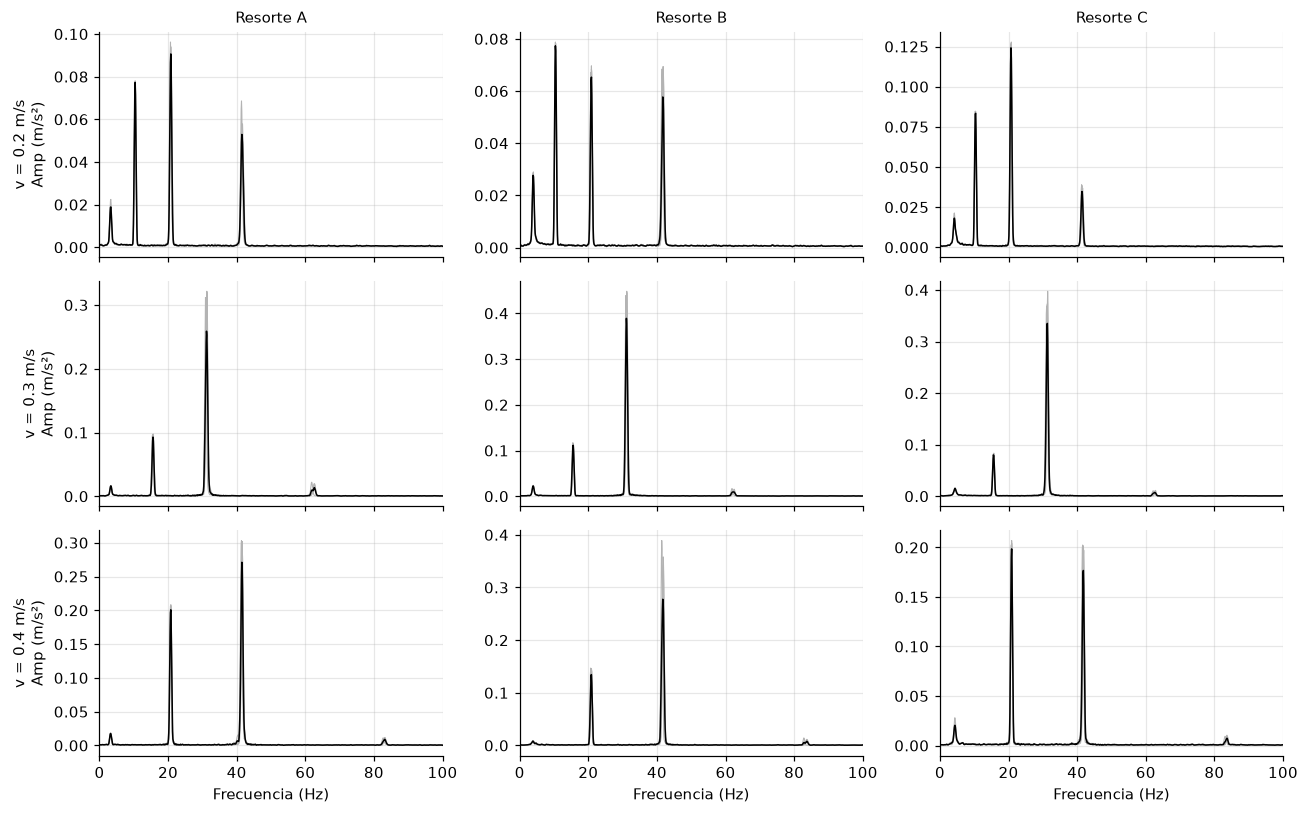

**Figura 7.** Espectros ADFT simulados fuera del puente, registrados con el teléfono (comparable a la Fig. 13 del artículo). Gris: los 3 recorridos de diseño; negro: su promedio, que se usa para construir el filtro.

In [14]:
def grid_axes(title_fmt="v = {v} m/s"):
    fig, axes = plt.subplots(3, 3, figsize=(12, 7.5), sharex=True)
    for i, v in enumerate(SPEEDS):
        axes[i, 0].set_ylabel(f"v = {v} m/s\nAmp (m/s²)")
    for j, sp in enumerate(K_SPRING):
        axes[0, j].set_title(f"Resorte {sp}", fontsize=10)
        axes[-1, j].set_xlabel("Frecuencia (Hz)")
    return fig, axes


fig, axes = grid_axes()
for i, v in enumerate(SPEEDS):
    for j, sp in enumerate(K_SPRING):
        ax = axes[i, j]
        for X in SPEC[("phone", (v, sp), "off")][:3]:
            ax.plot(freq, X, color="0.7", lw=0.7)
        ax.plot(freq, FILTERS[("phone", (v, sp))][1], color="k", lw=1)
        ax.set_xlim(0, 100)
fig.tight_layout()
show_figure(fig, 7, "Espectros ADFT simulados fuera del puente, registrados con el teléfono (comparable a la Fig. 13 del "
                    "artículo). Gris: los 3 recorridos de diseño; negro: su promedio, que se usa para construir el filtro.")

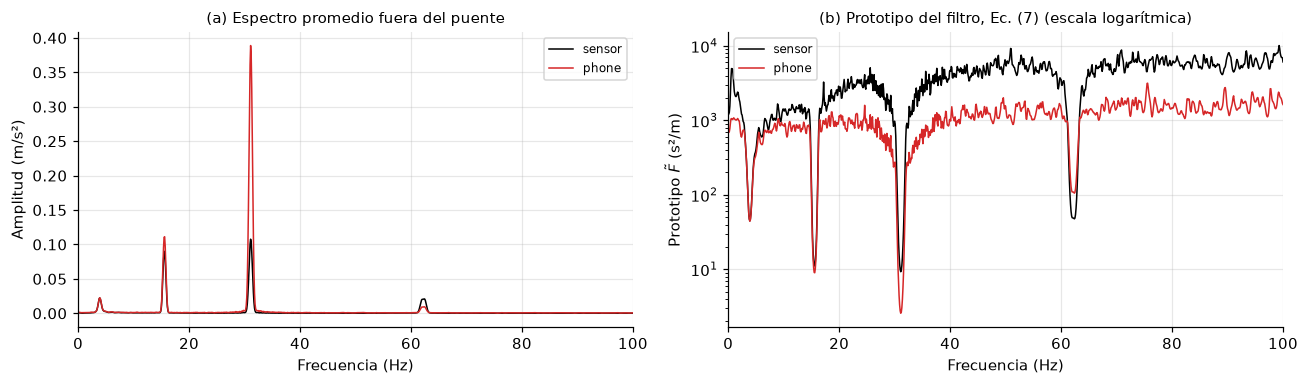

**Figura 8.** Espectro y prototipo del filtro del sensor y del teléfono para v = 0.3 m/s y resorte B (comparable a las Figs. 14–15 del artículo).

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
case = (0.3, "B")
for dev, col in (("sensor", "k"), ("phone", "tab:red")):
    F, X_bar = FILTERS[(dev, case)]
    axes[0].plot(freq, X_bar, color=col, lw=1, label=dev)
    axes[1].semilogy(freq, 1 / X_bar, color=col, lw=1, label=dev)
axes[0].set_ylabel("Amplitud (m/s²)")
axes[0].set_title("(a) Espectro promedio fuera del puente", fontsize=10)
axes[1].set_ylabel("Prototipo $\\tilde{F}$ (s²/m)")
axes[1].set_title("(b) Prototipo del filtro, Ec. (7) (escala logarítmica)", fontsize=10)
for ax in axes:
    ax.set_xlabel("Frecuencia (Hz)")
    ax.set_xlim(0, 100)
    ax.legend(fontsize=8)
fig.tight_layout()
show_figure(fig, 8, "Espectro y prototipo del filtro del sensor y del teléfono para v = 0.3 m/s y resorte B "
                    "(comparable a las Figs. 14–15 del artículo).")

**Lectura de las Figuras 7 y 8.**

- **Picos ligados a la velocidad.** Los picos principales son los armónicos del motor y se desplazan con la velocidad (≈ 10, 15 y 21 Hz y sus múltiplos), como en el artículo. El tipo de resorte cambia poco el espectro por encima de 5 Hz.
- **Filtro con forma inversa.** El prototipo es alto donde el espectro es bajo, y viceversa, y tiene valores del orden de cientos o miles de s²/m. Por eso hay que escalarlo (Ec. 9).
- **Filtro propio de cada dispositivo.** Los filtros del sensor y del teléfono difieren sobre todo por encima de 20 Hz: el teléfono tiene más ruido y amplifica cerca de su resonancia de montaje (35 Hz). El artículo destaca esta diferencia (Figs. 14–15) como razón para diseñar un filtro por dispositivo.

<a id="r-verif"></a>
### 6.2 Verificación del filtro con datos nuevos fuera del puente

**Qué se hizo.** El filtro de cada caso se aplicó a un 4.° recorrido fuera del puente que no se usó para diseñarlo (Sección 4.2 del artículo). Si el filtro captura bien al auto y al teléfono, el resultado debería ser plano, como ruido blanco (Figs. 16–17 del artículo).

Para medirlo se usa el **factor de pico**: el máximo del espectro dividido por su media en 0–100 Hz. Un espectro plano tiene un factor de pico bajo.

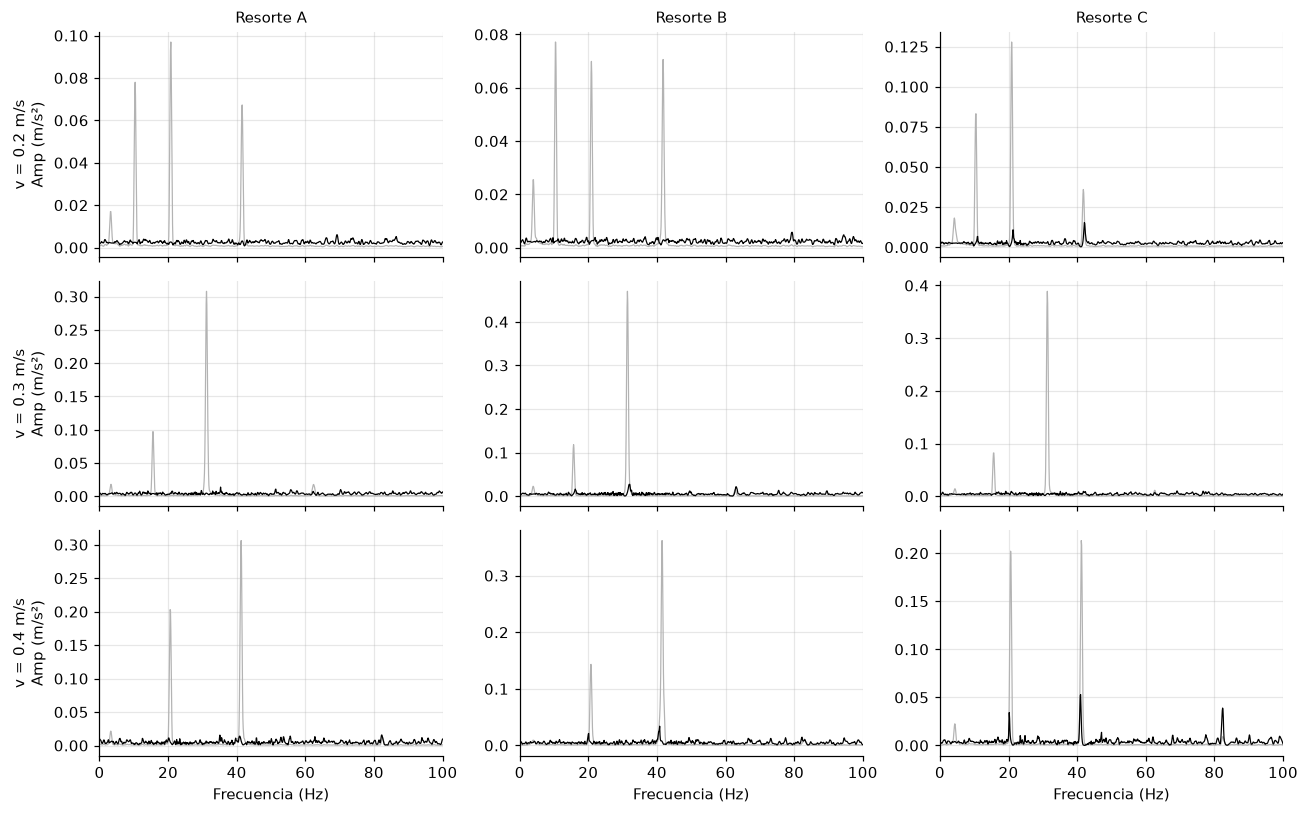

**Figura 9.** Espectros simulados del recorrido de verificación, registrado con el teléfono (comparable a la Fig. 17 del artículo). Gris: sin filtrar; negro: filtrado.

**Tabla 7.** Factor de pico (máximo / media en 0–100 Hz) del recorrido de verificación, antes y después de filtrar.

v (m/s),Resorte,sensor: sin filtrar,sensor: filtrado,phone: sin filtrar,phone: filtrado
0.20,A,49.25,2.03,39.93,2.40
0.20,B,48.37,2.30,32.62,2.40
0.20,C,52.83,5.86,50.98,5.77
0.30,A,43.95,2.20,78.29,3.41
0.30,B,56.81,7.89,92.47,5.16
0.30,C,60.98,2.77,93.34,2.41
0.40,A,49.46,4.83,66.19,3.22
0.40,B,55.99,6.67,72.18,6.64
0.40,C,56.25,17.90,56.06,12.40


In [16]:
fig, axes = grid_axes()
rows = []
for i, v in enumerate(SPEEDS):
    for j, sp in enumerate(K_SPRING):
        row = {"v (m/s)": v, "Resorte": sp}
        for dev in DEVICES:
            F, _ = FILTERS[(dev, (v, sp))]
            X_new = SPEC[(dev, (v, sp), "off")][3]
            Xf = F * X_new
            row[f"{dev}: sin filtrar"] = X_new.max() / X_new.mean()
            row[f"{dev}: filtrado"] = Xf.max() / Xf.mean()
            if dev == "phone":
                axes[i, j].plot(freq, X_new, color="0.7", lw=0.8)
                axes[i, j].plot(freq, Xf, color="k", lw=0.8)
                axes[i, j].set_xlim(0, 100)
        rows.append(row)
fig.tight_layout()
show_figure(fig, 9, "Espectros simulados del recorrido de verificación, registrado con el teléfono (comparable a la Fig. 17 "
                    "del artículo). Gris: sin filtrar; negro: filtrado.")
peak_factor = pd.DataFrame(rows)
show_table(peak_factor, 7, "Factor de pico (máximo / media en 0–100 Hz) del recorrido de verificación, antes y después de "
           "filtrar.", hide_index=True)

**Lectura.**

- **El filtro aplana el espectro.** Los picos del motor desaparecen y el espectro filtrado parece ruido. En 8 de los 9 casos, el factor de pico baja de 33–93 a 2–8, con el sensor y con el teléfono (Tabla 7). Es lo mismo que muestran las Figs. 16–17 del artículo.
- **Excepción y residuos.** En 0.4 m/s con resorte C el factor queda en 12–18 por picos residuales del motor. La velocidad de cada recorrido fluctúa un poco y los picos del motor son muy angostos, así que basta una pequeña diferencia con los recorridos de diseño para que no se cancelen del todo.

<a id="r-on"></a>
### 6.3 Aplicación del filtro sobre el puente

**Qué se hizo.** Se aplicó el filtro de cada caso a los 5 cruces del puente, Ec. (10), y se buscó el pico con mayor puntaje en 0.5–20 Hz (Figs. 18–19 del artículo).

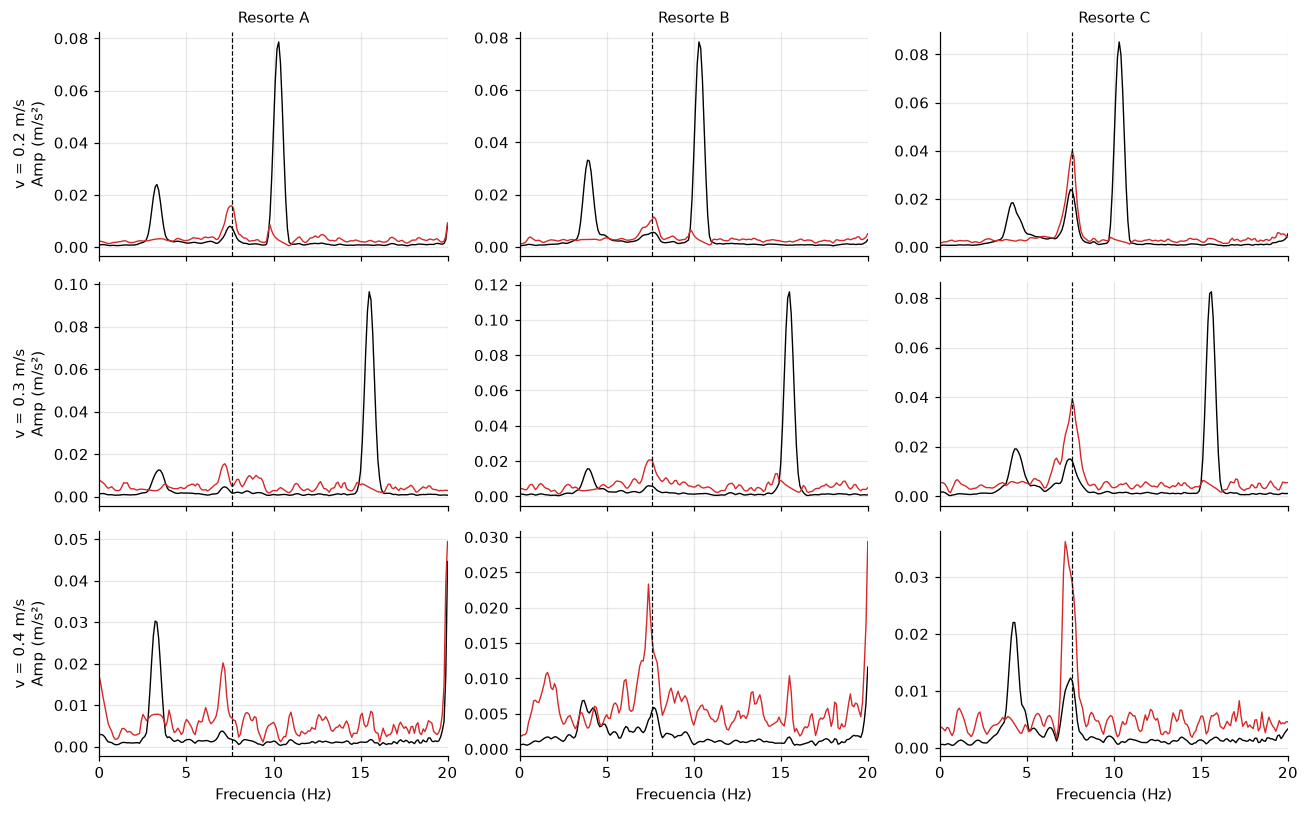

**Figura 10.** Espectros simulados de un cruce del puente, registrado con el teléfono (comparable a la Fig. 19 del artículo). Negro: sin filtrar; rojo: filtrado; línea discontinua: frecuencia del puente vacío (7.61 Hz).

In [17]:
fig, axes = grid_axes()
for i, v in enumerate(SPEEDS):
    for j, sp in enumerate(K_SPRING):
        ax = axes[i, j]
        F, _ = FILTERS[("phone", (v, sp))]
        Y = SPEC[("phone", (v, sp), "on")][0]
        sel = freq <= F_MAX
        ax.plot(freq[sel], Y[sel], color="k", lw=0.9)
        ax.plot(freq[sel], (F * Y)[sel], color="tab:red", lw=0.9)
        ax.axvline(F_BRIDGE, color="k", ls="--", lw=0.8)
        ax.set_xlim(0, F_MAX)
fig.tight_layout()
show_figure(fig, 10, "Espectros simulados de un cruce del puente, registrado con el teléfono (comparable a la Fig. 19 del "
                     "artículo). Negro: sin filtrar; rojo: filtrado; línea discontinua: frecuencia del puente vacío (7.61 Hz).")

In [18]:
def identify(dev, filters, spec, cases=CASES, filtered=True):
    # Best-scored peak of every crossing, per case
    out = {}
    for c in cases:
        F, _ = filters[(dev, c)]
        out[c] = [top_peak(freq, F * Y if filtered else Y) for Y in spec[(dev, c, "on")]]
    return out


ident = {(dev, flt): identify(dev, FILTERS, SPEC, filtered=flt) for dev in DEVICES for flt in (False, True)}
rows = []
for c in CASES:
    row = {"v (m/s)": c[0], "Resorte": c[1]}
    for dev in DEVICES:
        for flt, name in ((False, "sin filtrar"), (True, "filtrado")):
            fk = np.array(ident[(dev, flt)][c])
            row[f"{dev}: {name}"] = f"{np.median(fk):.1f} Hz ({np.sum(np.abs(fk - F_BRIDGE) < TOL)}/{fk.size})"
    rows.append(row)
show_table(pd.DataFrame(rows), 8, "Frecuencia del pico con mayor puntaje (mediana de los 5 cruces) y número de cruces que "
           f"identifican el puente (a menos de {TOL} Hz de {F_BRIDGE:.2f} Hz).", hide_index=True)


def success(dev, flt, ident_dict):
    fk = np.concatenate([ident_dict[(dev, flt)][c] for c in CASES])
    return 100 * np.mean(np.abs(fk - F_BRIDGE) < TOL)


filtered_peaks = np.concatenate([ident[("phone", True)][c] for c in CASES])
hits = filtered_peaks[np.abs(filtered_peaks - F_BRIDGE) < TOL]
print(f"Identified frequency when correct (phone): mean {hits.mean():.2f} Hz, range {hits.min():.1f}-{hits.max():.1f} Hz")

**Tabla 8.** Frecuencia del pico con mayor puntaje (mediana de los 5 cruces) y número de cruces que identifican el puente (a menos de 0.6 Hz de 7.61 Hz).

v (m/s),Resorte,sensor: sin filtrar,sensor: filtrado,phone: sin filtrar,phone: filtrado
0.20,A,10.3 Hz (0/5),7.4 Hz (5/5),10.3 Hz (0/5),7.5 Hz (5/5)
0.20,B,10.3 Hz (0/5),7.5 Hz (5/5),10.3 Hz (0/5),7.5 Hz (5/5)
0.20,C,10.3 Hz (0/5),7.6 Hz (5/5),10.3 Hz (0/5),7.6 Hz (5/5)
0.30,A,15.4 Hz (0/5),7.7 Hz (4/5),15.4 Hz (0/5),14.9 Hz (2/5)
0.30,B,15.4 Hz (0/5),7.6 Hz (5/5),15.4 Hz (0/5),7.6 Hz (5/5)
0.30,C,15.4 Hz (0/5),7.6 Hz (5/5),15.4 Hz (0/5),7.6 Hz (5/5)
0.40,A,3.2 Hz (0/5),7.3 Hz (5/5),3.2 Hz (0/5),7.2 Hz (4/5)
0.40,B,7.3 Hz (3/5),7.4 Hz (5/5),7.3 Hz (3/5),7.4 Hz (5/5)
0.40,C,4.4 Hz (0/5),7.3 Hz (5/5),4.4 Hz (0/5),7.2 Hz (5/5)


Identified frequency when correct (phone): mean 7.48 Hz, range 7.1-7.9 Hz


**Lectura.**

- **Sin filtrar gana el auto.** El pico con mayor puntaje es casi siempre del auto: el motor (10.3 y 15.4 Hz) a 0.2 y 0.3 m/s y la suspensión (3.2–4.4 Hz) a 0.4 m/s. Solo 3 de los 45 cruces identifican el puente sin filtro, todos a 0.4 m/s con el resorte B.
- **Con el filtro gana el puente.** El puente es el pico con mayor puntaje en 44 de 45 cruces con el sensor y en 41 de 45 con el teléfono (Tabla 8). En la Figura 10, la curva roja tiene su pico junto a la línea discontinua en los 9 casos, mientras que la negra está dominada por el motor.
- **Fallos por residuos del motor.** La mayoría de los fallos están en 0.3 m/s con el resorte A, donde el teléfono elige 14.9 Hz en 3 de 5 cruces. Es el armónico del motor (15.4 Hz fuera del puente) desplazado porque el auto va 1 % más lento sobre el puente. El artículo describe estos mismos picos residuales y su causa (Sección 4.3).
- **Frecuencia desplazada.** Cuando acierta, el pico está entre 7.1 y 7.9 Hz, con media 7.48 Hz, algo por debajo de los 7.61 Hz del puente vacío. Es el efecto de la masa del auto, que se suma a la del puente mientras lo cruza; el artículo también lo observa.
- **Sensor y teléfono rinden parecido**, como concluye el artículo.
- **Efecto de la velocidad.** El artículo observa que el puente se ve mejor a baja velocidad, porque las señales son más largas. La simulación no muestra esa tendencia en los espectros filtrados; sin filtrar, el puente se ve mejor a 0.4 m/s porque el pico principal del motor sale del rango 0–20 Hz.

<a id="r-score"></a>
### 6.4 Puntuación de picos

**Qué se hizo.** Con los espectros del teléfono, como en el artículo, se calculó el puntaje de cada pico, Ec. (12), y se promedió por intervalo de frecuencia entre los 45 cruces (9 casos × 5 cruces). Es el equivalente de las Figs. 20 y 21 del artículo.

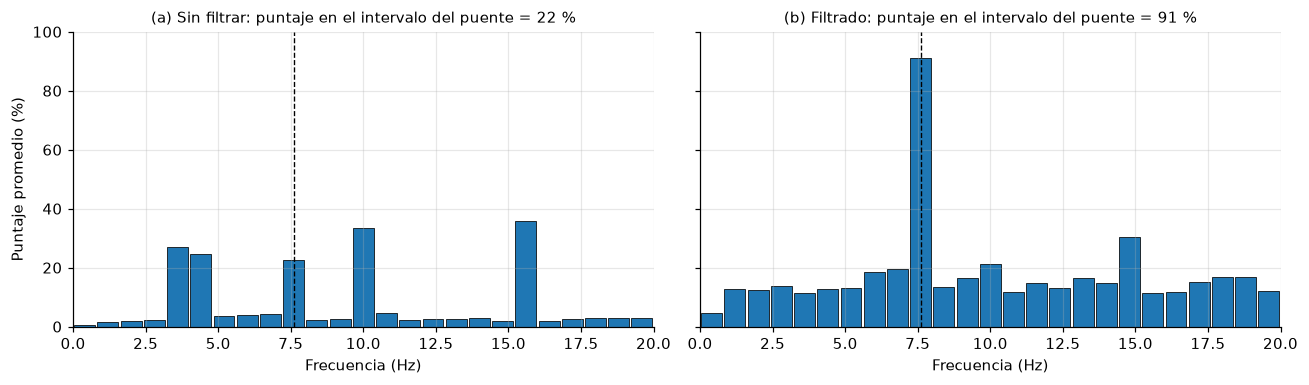

**Figura 11.** Histograma de puntajes promedio de los picos de los cruces simulados, teléfono (comparable a las Figs. 20–21 del artículo). Línea discontinua: frecuencia del puente vacío.

**Tabla 9.** Porcentaje de los 45 cruces simulados cuyo pico con mayor puntaje está a menos de 0.6 Hz de la frecuencia del puente.

Caso,Cruces que identifican el puente (%)
"Sensor, sin filtrar",7
"Sensor, filtrado",98
"Teléfono, sin filtrar",7
"Teléfono, filtrado",91
Teléfono filtrado con el filtro del sensor,91


In [19]:
def score_histogram(dev, filters, spec, filtered):
    hist = []
    for c in CASES:
        F, _ = filters[(dev, c)]
        for Y in spec[(dev, c, "on")]:
            f_pk, _, _, sc = peak_scores(freq, F * Y if filtered else Y)
            hist.append(binned_scores(f_pk, sc))
    return np.mean(hist, axis=0)


centers = EDGES[:-1] + BIN_W / 2
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, flt, name in ((axes[0], False, "(a) Sin filtrar"), (axes[1], True, "(b) Filtrado")):
    h = score_histogram("phone", FILTERS, SPEC, flt)
    ax.bar(centers, h, width=BIN_W * 0.9, color="tab:blue", edgecolor="k", lw=0.5)
    ax.axvline(F_BRIDGE, color="k", ls="--", lw=0.9)
    b = np.digitize(F_BRIDGE, EDGES) - 1
    ax.set_title(f"{name}: puntaje en el intervalo del puente = {h[b]:.0f} %", fontsize=10)
    ax.set_xlabel("Frecuencia (Hz)")
    ax.set_xlim(0, F_MAX)
    ax.set_ylim(0, 100)
axes[0].set_ylabel("Puntaje promedio (%)")
fig.tight_layout()
show_figure(fig, 11, "Histograma de puntajes promedio de los picos de los cruces simulados, teléfono (comparable a las "
                     "Figs. 20–21 del artículo). Línea discontinua: frecuencia del puente vacío.")

cross = {("phone", c): (FILTERS[("sensor", c)][0], None) for c in CASES}
ident_cross = {("phone", True): identify("phone", cross, SPEC)}
show_table(pd.DataFrame({
    "Caso": ["Sensor, sin filtrar", "Sensor, filtrado", "Teléfono, sin filtrar", "Teléfono, filtrado",
             "Teléfono filtrado con el filtro del sensor"],
    "Cruces que identifican el puente (%)": [success("sensor", False, ident), success("sensor", True, ident),
                                             success("phone", False, ident), success("phone", True, ident),
                                             success("phone", True, ident_cross)]}),
    9, "Porcentaje de los 45 cruces simulados cuyo pico con mayor puntaje está a menos de "
       f"{TOL} Hz de la frecuencia del puente.", precision=0, hide_index=True)

**Reportado por el artículo (Figs. 20–21, teléfono):** sin filtrar, el intervalo del puente tiene un puntaje promedio cercano a **56 %**, similar al de otros picos (≈ 57 % cerca de 18 Hz); después de filtrar llega al **100 %**: en todos los cruces, el pico más alto y más prominente fue el del puente. Los autores lo resumen como que el filtro "casi duplica la probabilidad" de detectar el puente.

**Lectura de la simulación.**

- **Misma tendencia que el artículo.** El puntaje promedio del intervalo del puente sube de 22 % sin filtrar a 91 % con filtro (Figura 11). Sin filtrar, los intervalos con más puntaje son los del auto: el motor a 10 y 15.6 Hz y la suspensión a 3–4 Hz.
- **Puntaje sin filtrar más bajo.** El 22 % es menor que el ≈ 56 % del artículo, porque en esta simulación el puente aporta menos a la vibración del auto que en el ensayo real.
- **El filtrado no llega a 100 %** por los residuos del motor descritos en la sección 6.3.
- **Filtro de otro dispositivo.** Usar en el teléfono el filtro diseñado con el sensor da el mismo 91 % (Tabla 9). En esta simulación, los dos dispositivos solo difieren por encima de 20 Hz, fuera de la banda donde se busca el puente. Un filtro propio de cada dispositivo es necesario solo cuando sus respuestas difieren **dentro** de la banda de interés; el artículo muestra que los filtros difieren (Figs. 14–15), pero no prueba qué pasa si se usa el filtro de otro dispositivo.

<a id="r-sens"></a>
### 6.5 Sensibilidad a los supuestos del método

Este análisis **no está en el artículo**. Los autores advierten que el método supone condiciones iguales fuera y sobre el puente (misma velocidad y rugosidad) y que la frecuencia del puente no esté cerca de las del auto, pero no lo prueban. Aquí se repiten los cruces cambiando un supuesto a la vez, con el teléfono y 3 cruces por caso:

- **Cambio de velocidad** sobre el puente: 0 %, 3 % y 5 % (base: 1 %). Se usan los filtros ya diseñados.
- **Rugosidad del puente** 2 y 4 veces la de la placa de referencia. Se usan los filtros ya diseñados.
- **Suspensión cerca del puente:** la lectura de 4 resortes en paralelo (6.6–8.6 Hz, Tabla 4). Requiere diseñar filtros nuevos.
- **Motor a la frecuencia del puente:** velocidad de 0.146 m/s, para que $f_m \approx 7.6$ Hz. Requiere filtros nuevos.

207 extra runs simulated in 33.0 s


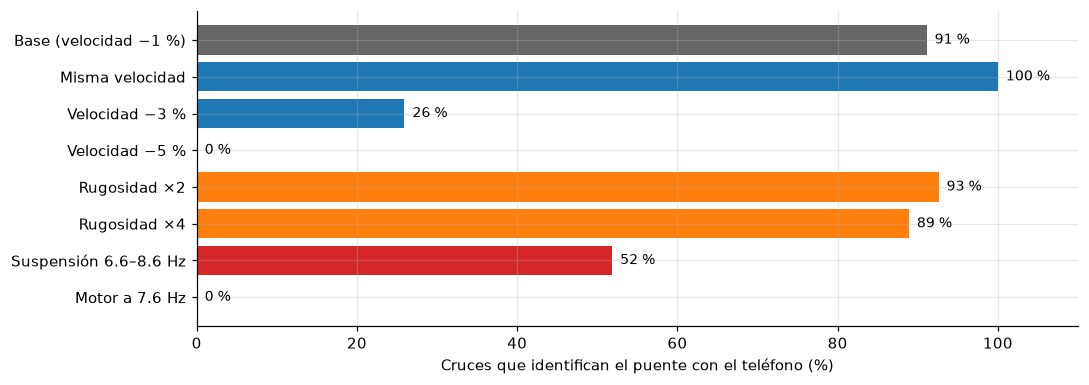

**Figura 12.** Sensibilidad del método a sus supuestos (simulación propia; no está en el artículo). Gris: caso base; azul: cambio de velocidad sobre el puente; naranja: rugosidad distinta; rojo: frecuencias del auto cerca de la del puente.

In [20]:
N_SENS = 3
t0 = time.time()
batches = {}
for drop in (0.0, 0.03, 0.05):
    name = "Misma velocidad" if drop == 0 else f"Velocidad −{drop * 100:.0f} %"
    batches[name] = ("base", make_runs(0, N_SENS, seed0=5000, speed_drop=drop))
for rough in (2.0, 4.0):
    batches[f"Rugosidad ×{rough:.0f}"] = ("base", make_runs(0, N_SENS, seed0=6000, rough_on=rough))
batches["Suspensión 6.6–8.6 Hz"] = ("new", make_runs(3, N_SENS, seed0=7000, k_factor=4.0))
batches["Motor a 7.6 Hz"] = ("new", make_runs(3, N_SENS, seed0=8000, speeds=[F_BRIDGE / C_MOTOR]))

# Simulate everything except the slow-speed batch together (the longest run sets the number of steps)
fast = [r for name, (_, rs) in batches.items() if name != "Motor a 7.6 Hz" for r in rs]
slow = batches["Motor a 7.6 Hz"][1]
sig_all = dict(zip(map(id, fast), simulate(fast)))
sig_all.update(zip(map(id, slow), simulate(slow)))
print(f"{len(fast) + len(slow)} extra runs simulated in {time.time() - t0:.1f} s")

sens = {"Base (velocidad −1 %)": success("phone", True, ident)}
for name, (filt_kind, rs) in batches.items():
    f_s, spec_s = spectra_of(rs, [sig_all[id(r)] for r in rs], seed=11)
    cases_s = sorted({r["case"] for r in rs})
    filt = FILTERS if filt_kind == "base" else {("phone", c): design_filter(spec_s[("phone", c, "off")][:3]) for c in cases_s}
    idt = identify("phone", filt, spec_s, cases=cases_s)
    fk = np.concatenate([idt[c] for c in cases_s])
    sens[name] = 100 * np.mean(np.abs(fk - F_BRIDGE) < TOL)

fig, ax = plt.subplots(figsize=(10, 3.6))
names = list(sens)
cols = ["0.4"] + ["tab:blue"] * 3 + ["tab:orange"] * 2 + ["tab:red"] * 2
ax.barh(names[::-1], [sens[n] for n in names][::-1], color=cols[::-1])
for k, n in enumerate(names[::-1]):
    ax.text(sens[n] + 1, k, f"{sens[n]:.0f} %", va="center", fontsize=9)
ax.set_xlim(0, 110)
ax.set_xlabel("Cruces que identifican el puente con el teléfono (%)")
fig.tight_layout()
show_figure(fig, 12, "Sensibilidad del método a sus supuestos (simulación propia; no está en el artículo). Gris: caso base; "
                     "azul: cambio de velocidad sobre el puente; naranja: rugosidad distinta; rojo: frecuencias del auto "
                     "cerca de la del puente.")

**Lectura.**

- **La velocidad es el supuesto más crítico.** Con la misma velocidad fuera y sobre el puente se acierta en el 100 % de los cruces; con 1 % menos, en el 91 %; con 3 %, en el 26 %; con 5 %, en ninguno. Los picos del motor son angostos y se mueven con la velocidad: un 3 % a 15.6 Hz son 0.5 Hz. Eso basta para que el pico de sobre el puente caiga en un valle del espectro de referencia, donde el filtro **amplifica** en lugar de borrar. Un auto real difícilmente mantiene la velocidad dentro de 1–2 % entre el tramo de referencia y el puente.
- **Rugosidad.** Duplicar o cuadruplicar la rugosidad del puente casi no cambia el resultado (93 % y 89 %). Pero en esta simulación la rugosidad aporta poco frente al motor. En un pavimento real, donde la rugosidad domina la vibración del vehículo, el efecto debería ser mayor; el artículo no lo estudia.
- **Suspensión cerca del puente.** Con la lectura de 4 resortes en paralelo (6.6–8.6 Hz), el acierto baja al 52 %. El auto y el puente quedan acoplados y el pico del puente cae sobre un pico de la referencia, que el filtro atenúa.
- **Motor a la frecuencia del puente.** Ningún cruce acierta: el filtro borra el pico del motor y, con él, el del puente. Confirma la condición que declaran los autores: la frecuencia del puente no debe estar cerca de las frecuencias principales del auto.

<a id="conclusiones"></a>
## 7. Conclusiones y limitaciones

### Conclusiones del artículo

1. Se propone, por primera vez según los autores, un método de **filtrado inverso** para identificar indirectamente la frecuencia de un puente: el espectro de fuera del puente se usa para filtrar el de sobre el puente.
2. En el laboratorio, el filtro **suprime las frecuencias del auto y resalta la del puente** en las 9 combinaciones de velocidad y suspensión.
3. Como el filtro se diseña para cada dispositivo en cada auto, el método es **robusto frente a sus características**: no hace falta conocer las propiedades del auto ni del teléfono.
4. Aunque el teléfono es menos preciso que el acelerómetro de referencia, su filtro propio compensa esa diferencia y la frecuencia del puente se identifica con ambos.
5. El filtro casi duplica el puntaje promedio del pico del puente; en todos los cruces, el pico más alto y más prominente filtrado fue el del puente.

### Limitaciones declaradas por los autores

- El método funciona mientras la frecuencia del puente **no esté cerca** de las frecuencias principales del auto.
- Supone **misma velocidad y misma rugosidad** fuera y sobre el puente; ambos factores cambian mucho el espectro y deben estudiarse.
- Las señales eran **cortas** (4–6 s); con señales más largas el espectro y el filtro deberían mejorar.
- Pequeños picos residuales aparecen porque la **velocidad del auto cambia** sobre el puente (la deformación del tablero lo frena).
- La frecuencia identificada está **desplazada** respecto de la del puente vacío por la masa del auto; cuánto y por qué queda fuera del alcance.
- Las frecuencias del teléfono están más desplazadas que las del sensor; debe mejorarse en el futuro.

### Limitaciones identificadas en este análisis

- **El supuesto de condiciones iguales es muy exigente.** La referencia tiene que registrarse con la misma velocidad, la misma superficie y el teléfono en la misma posición. En la simulación, un cambio de velocidad de 3 % baja el acierto del 91–100 % al 26 %, y uno de 5 % lo anula (sección 6.5). El artículo reconoce el supuesto, pero no mide su efecto.
- **El cociente no está regularizado.** Dividir por el espectro de referencia amplifica las frecuencias donde ese espectro es bajo, que es donde domina el ruido. El espectro filtrado "parecido a ruido blanco" de la verificación es precisamente un espectro blanqueado. El artículo no discute regularización (p. ej. Wiener) ni cómo evitar picos falsos por valles de la referencia.
- **Resolución sobrestimada.** Los "0.1 Hz de resolución" son solo la separación entre puntos del relleno con ceros. La resolución real con ventanas de 3 s es ≈ 0.33 Hz, y con señales de 4–8 s solo hay 2–7 ventanas para promediar.
- **Errores de notación y de referencias.**
    - La Ec. 5 no desplaza la señal en cada ventana ni toma el valor absoluto.
    - La Ec. 8 usa $\bar{Y}$ para el promedio del espectro de fuera del puente.
    - El texto atribuye el acoplamiento a la "Ecuación (2)" en lugar de la (1).
    - En la Ec. 1, la prima se define como derivada en el tiempo, pero la derivada cuarta es en el espacio.
    - En la Sección 4.1, las referencias a figuras están cruzadas: los filtros se citan en las Figs. 12–13 en lugar de las 14–15, y los espectros en las 16–17 en lugar de las 12–13.
- **Propiedades del auto incompletas.** No se reporta la frecuencia de la suspensión, y no queda claro si la rigidez es de cada resorte o del conjunto. Con 4 resortes en paralelo, el auto vibraría a 6.6–8.6 Hz, alrededor de la frecuencia del puente: justo la condición en la que el método no debería funcionar. En la simulación, esa lectura baja el acierto al 52 %.
- **Resultados cualitativos.** No se reportan:
    - el valor numérico de la frecuencia del puente ni una tabla de frecuencias identificadas;
    - cuánto se desplaza la frecuencia;
    - cuántos cruces se hicieron por caso;
    - cómo se combinan los puntajes de amplitud y prominencia, ni el ancho de los intervalos.

  El "100 % de las veces" se basa en un número de cruces que no se informa.
- **Duraciones inconsistentes.** Las señales se describen como de 4–8 s y de 4–6 s, pero cruzar 2 m a 0.2 m/s toma 10 s.
- **Alcance limitado.** Un solo puente de laboratorio y un solo auto, cuyo motor genera picos muy marcados; relación de masas de 3.8 %. Solo se identifica la frecuencia fundamental: no hay detección de daño, varios vehículos a la vez ni efectos de temperatura.
- **El problema de fondo sigue abierto en la práctica.** En un puente real, la frecuencia de rebote de los autos (≈ 1–3 Hz) y la de sus ruedas (≈ 10–15 Hz) caen en el rango de muchos puentes. Justo ahí el método no funciona.
- **Reproducción parcial.** La simulación usa parámetros supuestos (Tabla 6). Reproduce la tendencia principal (del 22 % al 91 % de puntaje en el intervalo del puente), pero no los valores del artículo (≈ 56 % y 100 %) ni su observación de que el puente se ve mejor a baja velocidad.
- **Datos no públicos.**

[↑ Volver al índice](#indice)